# 🌋 Volcanic Activity Prediction Using Satellite Imagery
## Binary Classification: Active vs. Dormant Volcanoes

**Author:** Vinicius Quintana

**Collaborator:** Claude & Google Gemini

---

### Project Overview

This project implements a **deep learning pipeline** for classifying satellite image patches of volcanoes as either **active** (emitting smoke/ash) or **dormant**. The architecture combines:

1. **ResNet-18** (pretrained on ImageNet, fine-tuned) as the visual backbone (512-D features)
2. **Laplacian of Gaussian (LoG) Edge Detector** — a classical computer vision component that computes a smoke-vs-cloud score per image
3. **Fusion Classifier** — concatenates the 512-D backbone features with the 1-D smoke weight → FC layers → Sigmoid

```
Image → Augmentation → ResNet-18 Backbone (512-D) ─┐
     └→ LaplaceEdgeDetector (1-D smoke weight)  ───┤ → Fusion FC → Sigmoid → P(active)
```

### Dataset
- **3,200 satellite image patches** (224×224 RGB) from Sentinel-2 and Landsat-8
- **Balanced classes:** Active (YesActivity) and Dormant (NoActivity)
- Train: 2,400 images | Test: 600 images | Validation: 15% of train split

### Modifications from Original Proposal

1. **Benchmark analysis:** compared against published results (DCNNVA, SqueezeNet, ResNet-50, VGG-16/19, DenseNet-121, MobileNet, InceptionV3).
2. **Integrated diagnostics:** Grad-CAM, t-SNE, TTA and threshold tuning, originally a separate `diagnostics.py`, are now notebook sections.
3. **Scene-grouped validation split:** a perceptual-hash audit (dHash) found that a random split put near-duplicate scenes in both train and validation (145 of 360 validation images within 4 bits of a training image). Training images are now clustered into 906 scene groups and each group is kept on one side of the split.
4. **Validation-based threshold tuning:** the decision threshold τ is tuned on the validation set only, never on test. I initially tuned it on test (100% accuracy), which leaks test information, so I removed it.
5. **Robustness safeguards:** train/val/test deduplication audit, out-of-distribution stress test (V1 dataset), and an occlusion-sensitivity test.
6. **Colab-compatible paths.**

---

## Section 1: Imports

All library imports for the entire notebook are consolidated here for clarity and PEP8 compliance.

In [1]:
# ── Standard library ──────────────────────────────────────────────
import os
import sys
import time
import math
import random
import warnings

# ── Numerical / image processing ──────────────────────────────────
import numpy as np
import cv2
from PIL import Image

# ── Deep learning ─────────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms, models

In [2]:
# ── Visualization ─────────────────────────────────────────────────
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import seaborn as sns

# ── Scikit-learn metrics ──────────────────────────────────────────
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score, roc_curve,
    classification_report, precision_recall_curve,
    average_precision_score
)
from sklearn.manifold import TSNE

# ── Pandas for benchmark tables ───────────────────────────────────
import pandas as pd

warnings.filterwarnings("ignore")

In [3]:
# ── Visualization defaults for publication-quality plots ──────────
sns.set_theme(
    style="whitegrid",
    palette="colorblind",
    font_scale=1.1
)
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 150,
    "figure.figsize": (10, 6),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
})
print("All imports loaded successfully.")

All imports loaded successfully.


## Section 2: Reproducibility & Configuration

Seeds and hyperparameters are set globally to ensure deterministic, reproducible results.

In [4]:
# ── Reproducibility seeds ────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print(f"Random seed set to {SEED} for reproducibility.")

Random seed set to 42 for reproducibility.


In [5]:
# ── Configuration class ──────────────────────────────────────────
class Config:
    """Central configuration for all hyperparameters and paths."""
    DATA_ROOT = "data/Volcanic_Dataset"
    # Primary 3,200-image dataset (Volcanic_V2)
    TRAIN_DIR = os.path.join(DATA_ROOT, "Volcanic_V2", "Volcanic_V2_Test_Train", "train")
    TEST_DIR = os.path.join(DATA_ROOT, "Volcanic_V2", "Volcanic_V2_Test_Train", "test")
    # Auxiliary 200-image dataset (Volcanic)
    V1_DIR = os.path.join(DATA_ROOT, "Volcanic", "Volcanic")

    # Training hyperparameters
    IMAGE_SIZE = 224
    BATCH_SIZE = 32
    NUM_EPOCHS = 30
    LEARNING_RATE = 1e-4
    WEIGHT_DECAY = 1e-4
    VAL_SPLIT = 0.15
    DROPOUT_RATE = 0.4

    # Laplace edge detector settings
    LAPLACE_BLUR_KSIZE = 5
    LAPLACE_SMOKE_THRESHOLD = 0.35

    # Output directories
    OUTPUT_DIR = "outputs"
    MODEL_SAVE = os.path.join(OUTPUT_DIR, "best_volcano_model.pth")
    PLOT_DIR = os.path.join(OUTPUT_DIR, "plots")

    # Device selection
    DEVICE = torch.device(
        "mps" if torch.backends.mps.is_available() else
        "cuda" if torch.cuda.is_available() else "cpu"
    )

os.makedirs(Config.OUTPUT_DIR, exist_ok=True)
os.makedirs(Config.PLOT_DIR, exist_ok=True)
print(f"Device: {Config.DEVICE}")
print(f"Epochs: {Config.NUM_EPOCHS}, BS: {Config.BATCH_SIZE}, LR: {Config.LEARNING_RATE}")


Device: cuda
Epochs: 30, BS: 32, LR: 0.0001


## Section 3: Laplacian Edge Detector (Smoke vs. Cloud)

This classical computer vision component uses the **Laplacian of Gaussian (LoG)** operator to distinguish volcanic smoke from clouds:
- **High LoG energy** → sharp, irregular, fractal-like edges → volcanic smoke/ash plumes
- **Low LoG energy** → smooth, rounded blobs → cloud formations

The resulting scalar weight is injected into the fusion classifier as an auxiliary feature.

In [6]:
class LaplaceEdgeDetector:
    """Applies Laplacian of Gaussian to compute edge energy and smoke score."""
    def __init__(self, blur_ksize=5, threshold=0.35):
        self.blur_ksize = blur_ksize
        self.threshold = threshold

    def compute_edge_energy(self, img_np):
        """Normalised Laplacian variance in [0, 1]."""
        gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
        blur = cv2.GaussianBlur(gray, (self.blur_ksize, self.blur_ksize), 0)
        variance = cv2.Laplacian(blur, cv2.CV_64F).var()
        return float(np.tanh(variance / 500.0))

    def smoke_weight(self, img_np):
        """Returns smoke score in [0, 1] (0 = cloud, 1 = smoke)."""
        energy = self.compute_edge_energy(img_np)
        weight = max(0.0, (energy - self.threshold) / (1.0 - self.threshold))
        return min(weight, 1.0)

    def visualise(self, img_np, save_path=None):
        """Visualise original, LoG map, and overlay heatmap."""
        gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
        blur = cv2.GaussianBlur(gray, (self.blur_ksize, self.blur_ksize), 0)
        lap = cv2.Laplacian(blur, cv2.CV_64F)
        abs_lap = np.uint8(np.clip(np.abs(lap) / (np.abs(lap).max() + 1e-8) * 255, 0, 255))
        heatmap = cv2.applyColorMap(abs_lap, cv2.COLORMAP_JET)
        overlay = cv2.addWeighted(img_np, 0.6, cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB), 0.4, 0)
        fig, axes = plt.subplots(1, 3, figsize=(14, 4))
        for ax, im, title in zip(axes, [img_np, abs_lap, overlay], ["Original", "LoG", "Overlay"]):
            ax.imshow(im, cmap="hot" if title == "LoG" else None)
            ax.set_title(title); ax.axis("off")
        plt.suptitle(f"Energy: {self.compute_edge_energy(img_np):.3f} | Smoke: {self.smoke_weight(img_np):.3f}")
        plt.tight_layout()
        if save_path: plt.savefig(save_path, dpi=150, bbox_inches="tight")
        plt.show()


## Section 4: Dataset Loading & Preprocessing

The dataset loader reads satellite image patches from a directory tree and:
1. Computes the Laplace smoke weight on the **original** (un-augmented) image
2. Applies augmentation/normalisation transforms
3. Returns a triplet: `(image_tensor, smoke_weight, label)`

### Colab Dataset Setup & Unzipping

If running in Google Colab, upload your zipped dataset (e.g. `Volcanic_Dataset.zip`) using the Colab file browser, or mount your Google Drive. The script below will automatically detect any uploaded `.zip` archive, extract it into the working directory, and dynamically resolve the train/test folder paths regardless of how they are nested.

In [7]:
# ── Unzip dataset archive in Colab or local runtime ──────────────
import zipfile
import glob
import shutil

# Find any zip files in the current environment
zip_files = glob.glob("*.zip") + glob.glob("data/*.zip")

if not os.path.exists(Config.TRAIN_DIR):
    if zip_files:
        target_zip = zip_files[0]
        print(f"Found dataset archive: {target_zip}. Extracting...")
        with zipfile.ZipFile(target_zip, 'r') as archive:
            archive.extractall("data")
        print("Extraction complete.")
    else:
        print("No zip file found automatically in current directory.")
        print("Please upload Volcanic_Dataset.zip to /content/ if in Colab.")
else:
    print(f"Dataset already found at {Config.TRAIN_DIR}")

# Clean up macOS metadata folder if created during unzipping
macosx_path = "data/__MACOSX"
if os.path.exists(macosx_path):
    shutil.rmtree(macosx_path, ignore_errors=True)
if os.path.exists("__MACOSX"):
    shutil.rmtree("__MACOSX", ignore_errors=True)


Found dataset archive: data.zip. Extracting...
Extraction complete.


In [8]:
# ── Dynamically discover dataset directories if nested ───────────
def find_split_dir(split_name):
    """Finds exact split directory by checking the directory name."""
    for root, dirs, _ in os.walk("."):
        if "__MACOSX" in root:
            continue
        if "YesActivity" in dirs and "NoActivity" in dirs:
            # Check the immediate folder name (e.g. 'train' or 'test')
            if os.path.basename(os.path.normpath(root)).lower() == split_name.lower():
                return root
    return None

discovered_train = find_split_dir("train")
discovered_test = find_split_dir("test")

if discovered_train:
    Config.TRAIN_DIR = discovered_train
if discovered_test:
    Config.TEST_DIR = discovered_test

print(f"TRAIN_DIR: {Config.TRAIN_DIR} (Found: {os.path.exists(Config.TRAIN_DIR)})")
print(f"TEST_DIR : {Config.TEST_DIR} (Found: {os.path.exists(Config.TEST_DIR)})")


TRAIN_DIR: ./data/data/Volcanic_Dataset/Volcanic_V2/Volcanic_V2_Test_Train/train (Found: True)
TEST_DIR : ./data/data/Volcanic_Dataset/Volcanic_V2/Volcanic_V2_Test_Train/test (Found: True)


In [9]:
class VolcanoDataset(Dataset):
    """Loads volcano satellite patches (YesActivity=1, NoActivity=0)."""
    CLASSES = {"NoActivity": 0, "YesActivity": 1}

    def __init__(self, root_dir, transform=None, laplace_detector=None):
        self.root_dir = root_dir
        self.transform = transform
        self.laplace = laplace_detector or LaplaceEdgeDetector()
        self.samples = []
        for class_name, label in self.CLASSES.items():
            class_dir = os.path.join(root_dir, class_name)
            if not os.path.isdir(class_dir):
                continue
            for fname in sorted(os.listdir(class_dir)):
                if fname.startswith(".") or "__MACOSX" in class_dir:
                    continue
                if fname.lower().endswith((".png", ".jpg", ".jpeg", ".tif")):
                    self.samples.append((os.path.join(class_dir, fname), label))
        active = sum(1 for _, l in self.samples if l == 1)
        dormant = sum(1 for _, l in self.samples if l == 0)
        print(f"Loaded {len(self.samples)} from {root_dir} (Active: {active}, Dormant: {dormant})")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        pil_img = Image.open(path).convert("RGB")
        smoke_w = self.laplace.smoke_weight(np.array(pil_img))
        smoke_t = torch.tensor([smoke_w], dtype=torch.float32)  # [1-D scalar]
        img_t = self.transform(pil_img) if self.transform else transforms.ToTensor()(pil_img)
        return img_t, smoke_t, torch.tensor(label, dtype=torch.long)


### Data Augmentation & Normalisation Transforms

Training uses aggressive augmentation (flips, rotations, color jitter, random grayscale for thermal-band simulation). Evaluation uses only resize + ImageNet normalisation.

In [10]:
# ImageNet statistics (backbone was pretrained on ImageNet)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def get_train_transforms(image_size=224):
    """Augmentation pipeline for training data."""
    return transforms.Compose([
        transforms.Resize((image_size + 32, image_size + 32)),
        transforms.RandomCrop(image_size),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.3),
        transforms.RandomRotation(degrees=30),
        transforms.ColorJitter(
            brightness=0.3, contrast=0.3,
            saturation=0.2, hue=0.05
        ),
        transforms.RandomGrayscale(p=0.05),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN, std=IMAGENET_STD
        ),
    ])

In [11]:
def get_eval_transforms(image_size=224):
    """Deterministic pipeline for evaluation data."""
    return transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN, std=IMAGENET_STD
        ),
    ])

### Load and Split Dataset

In [12]:
# Instantiate the Laplace detector
detector = LaplaceEdgeDetector(
    blur_ksize=Config.LAPLACE_BLUR_KSIZE,
    threshold=Config.LAPLACE_SMOKE_THRESHOLD
)

# Load full training dataset
print("Loading datasets...")
full_train_ds = VolcanoDataset(
    Config.TRAIN_DIR,
    transform=get_train_transforms(Config.IMAGE_SIZE),
    laplace_detector=detector
)

# Load test dataset
test_ds = VolcanoDataset(
    Config.TEST_DIR,
    transform=get_eval_transforms(Config.IMAGE_SIZE),
    laplace_detector=detector
)


Loading datasets...
Loaded 2400 from ./data/data/Volcanic_Dataset/Volcanic_V2/Volcanic_V2_Test_Train/train (Active: 1200, Dormant: 1200)
Loaded 600 from ./data/data/Volcanic_Dataset/Volcanic_V2/Volcanic_V2_Test_Train/test (Active: 300, Dormant: 300)


In [13]:
# ── Scene-grouped train / validation split (prevents near-duplicate leakage) ──
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import Subset

def compute_dhash(image, hash_size=8):
    resized = image.convert("L").resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS)
    diff = np.asarray(resized)[:, 1:] > np.asarray(resized)[:, :-1]
    return diff.flatten()

GROUP_DIST = 10  # < 11, the smallest test-to-train distance observed in the audit

print("Hashing training images to find scene groups...")
H = np.stack([compute_dhash(Image.open(p)) for p, _ in full_train_ds.samples]).astype(np.int16)
dist = H.shape[1] - (H @ H.T + (1 - H) @ (1 - H).T)
n_groups, groups = connected_components(csr_matrix(dist <= GROUP_DIST), directed=False)
sizes = np.bincount(groups)
print(f"{len(H)} images -> {n_groups} scene groups (largest: {sizes.max()} images)")

y_all = np.array([l for _, l in full_train_ds.samples])
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)  # 1/7 ≈ 14% ≈ VAL_SPLIT
train_idx, val_idx = next(sgkf.split(np.zeros(len(y_all)), y_all, groups))
assert not set(groups[train_idx]) & set(groups[val_idx]), "group leaked across split"

train_ds = Subset(full_train_ds, train_idx.tolist())
val_base = VolcanoDataset(                      # same files, no augmentation
    Config.TRAIN_DIR, transform=get_eval_transforms(Config.IMAGE_SIZE), laplace_detector=detector
)
val_ds = Subset(val_base, val_idx.tolist())
val_ds.dataset = val_base                       # keeps later `val_ds.dataset.samples` working

n_train, n_val = len(train_ds), len(val_ds)
print(f"\nTrain: {n_train} | Val: {n_val} | Test: {len(test_ds)}")
print(f"Val class balance: Active={int(y_all[val_idx].sum())}, Dormant={int((1 - y_all[val_idx]).sum())}")

Hashing training images to find scene groups...
2400 images -> 906 scene groups (largest: 16 images)
Loaded 2400 from ./data/data/Volcanic_Dataset/Volcanic_V2/Volcanic_V2_Test_Train/train (Active: 1200, Dormant: 1200)

Train: 2025 | Val: 375 | Test: 600
Val class balance: Active=218, Dormant=157


In [14]:
# Create DataLoaders
train_loader = DataLoader(
    train_ds, batch_size=Config.BATCH_SIZE,
    shuffle=True, num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_ds, batch_size=Config.BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    test_ds, batch_size=Config.BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)
print("DataLoaders created.")

DataLoaders created.


### Visualize Sample Data & Class Distribution

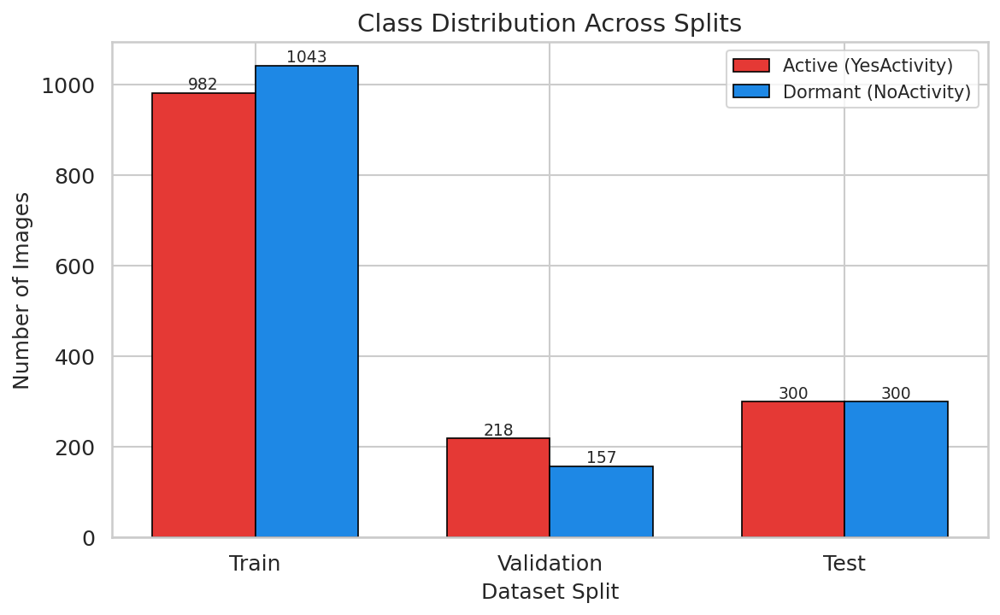

In [15]:
# ── Class distribution bar plot ──────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

# Count per split
splits = ["Train", "Validation", "Test"]
active_counts = [
    sum(1 for i in train_ds.indices
        if full_train_ds.samples[i][1] == 1),
    sum(1 for i in val_ds.indices
        if full_train_ds.samples[i][1] == 1),
    sum(1 for _, l in test_ds.samples if l == 1)
]
dormant_counts = [
    sum(1 for i in train_ds.indices
        if full_train_ds.samples[i][1] == 0),
    sum(1 for i in val_ds.indices
        if full_train_ds.samples[i][1] == 0),
    sum(1 for _, l in test_ds.samples if l == 0)
]

x = np.arange(len(splits))
width = 0.35
bars1 = ax.bar(
    x - width / 2, active_counts, width,
    label="Active (YesActivity)", color="#E53935",
    edgecolor="black", linewidth=0.8
)
bars2 = ax.bar(
    x + width / 2, dormant_counts, width,
    label="Dormant (NoActivity)", color="#1E88E5",
    edgecolor="black", linewidth=0.8
)
ax.set_xlabel("Dataset Split")
ax.set_ylabel("Number of Images")
ax.set_title("Class Distribution Across Splits")
ax.set_xticks(x)
ax.set_xticklabels(splits)
ax.legend()
for bar in list(bars1) + list(bars2):
    ax.text(
        bar.get_x() + bar.get_width() / 2., bar.get_height(),
        f"{int(bar.get_height())}",
        ha="center", va="bottom", fontsize=9
    )
plt.tight_layout()
plt.show()



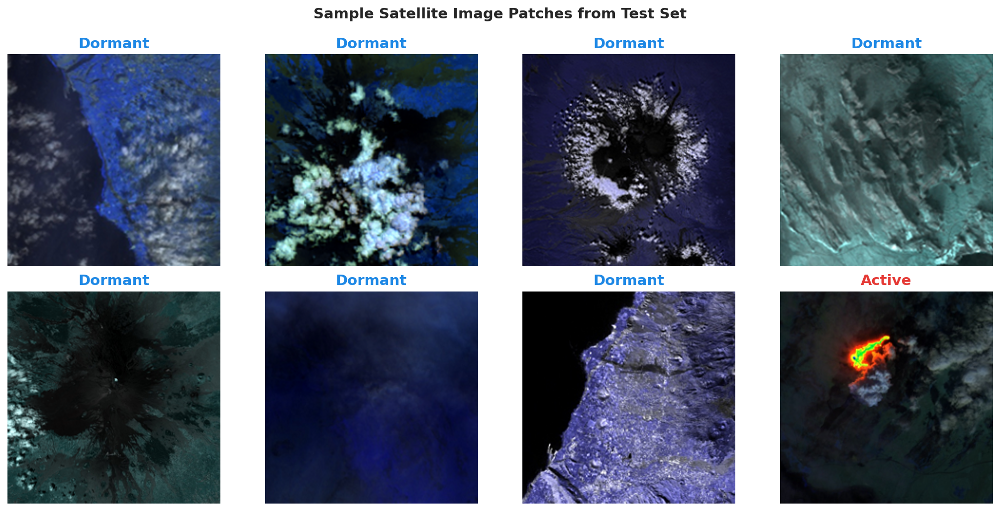

In [16]:
# ── Sample images grid ───────────────────────────────────────────
sample_indices = random.sample(range(len(test_ds)), 8)
fig2, axes2 = plt.subplots(2, 4, figsize=(14, 7))

for idx, si in enumerate(sample_indices):
    path, label = test_ds.samples[si]
    img = Image.open(path).convert("RGB")
    row, col = idx // 4, idx % 4
    axes2[row, col].imshow(img)
    cls = "Active" if label == 1 else "Dormant"
    color = "#E53935" if label == 1 else "#1E88E5"
    axes2[row, col].set_title(cls, color=color, fontweight="bold")
    axes2[row, col].axis("off")

fig2.suptitle(
    "Sample Satellite Image Patches from Test Set",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()


## Section 5: Model Architecture

The **VolcanoClassifier** fuses two information streams:
1. **Backbone (ResNet-18):** 512-D feature vector from ImageNet-pretrained ResNet-18
2. **Smoke weight (1-D):** Laplacian edge-energy scalar

The fusion classifier head: `FC(513→256) → BN → ReLU → Dropout(0.4) → FC(256→64) → BN → ReLU → Dropout(0.2) → FC(64→1) → Sigmoid`

In [17]:
class VolcanoClassifier(nn.Module):
    """ResNet-18 Backbone fused with 1-D LoG smoke scalar."""
    def __init__(self, dropout_rate=0.4, freeze_backbone=False):
        super().__init__()
        backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        in_features = backbone.fc.in_features  # 512
        backbone.fc = nn.Identity()
        self.backbone = backbone
        if freeze_backbone:
            for p in self.backbone.parameters(): p.requires_grad = False

        # Fusion input: 512 (ResNet) + 1 (LoG Smoke Weight) = 513 dimensions
        fusion_in = in_features + 1
        self.classifier = nn.Sequential(
            nn.Linear(fusion_in, 256), nn.BatchNorm1d(256), nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_rate),
            nn.Linear(256, 64), nn.BatchNorm1d(64), nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_rate / 2),
            nn.Linear(64, 1), nn.Sigmoid()
        )
        for m in self.classifier.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                if m.bias is not None: nn.init.zeros_(m.bias)

    def forward(self, image, smoke_weight):
        feats = self.backbone(image)
        return self.classifier(torch.cat([feats, smoke_weight], dim=1))

model = VolcanoClassifier(dropout_rate=Config.DROPOUT_RATE).to(Config.DEVICE)
total_p = sum(p.numel() for p in model.parameters())
trainable_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params: {total_p:,} | Trainable params: {trainable_p:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 207MB/s]


Total params: 11,325,249 | Trainable params: 11,325,249


## Section 6: Training Utilities

Includes early stopping, single-epoch training, and evaluation functions.

In [18]:
class EarlyStopping:
    """Stop training when validation loss stops improving."""

    def __init__(self, patience=7, min_delta=1e-4,
                 save_path=None):
        self.patience = patience
        self.min_delta = min_delta
        self.save_path = save_path
        self.best_loss = float("inf")
        self.counter = 0
        self.triggered = False

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            if self.save_path:
                torch.save(
                    model.state_dict(), self.save_path
                )
                print(f"  Best model saved -> {self.save_path}")
        else:
            self.counter += 1
            print(f"  EarlyStopping: {self.counter}/"
                  f"{self.patience}")
            if self.counter >= self.patience:
                self.triggered = True
        return self.triggered

In [19]:
def train_one_epoch(model, loader, criterion,
                    optimizer, device, epoch, total):
    """Run one full training epoch."""
    model.train()
    running_loss = 0.0
    correct = 0
    total_samples = 0

    for batch_idx, (images, smoke_w, labels) in enumerate(loader):
        images = images.to(device)
        smoke_w = smoke_w.to(device)
        labels = labels.float().unsqueeze(1).to(device)

        optimizer.zero_grad()
        preds = model(images, smoke_w)
        loss = criterion(preds, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predicted = (preds.detach() >= 0.5).long()
        correct += (
            predicted.squeeze() == labels.squeeze().long()
        ).sum().item()
        total_samples += images.size(0)

    avg_loss = running_loss / total_samples
    accuracy = correct / total_samples
    return avg_loss, accuracy

In [20]:
@torch.no_grad()
def evaluate(model, loader, criterion, device, threshold=0.5):
    """Evaluate model and collect full prediction arrays."""
    model.eval()
    if len(loader.dataset) == 0:
        print("  [ERROR] DataLoader dataset is empty (0 samples). Check directory path!")
        return {"loss": 0.0, "accuracy": 0.0, "precision": 0.0, "recall": 0.0, "f1": 0.0, "auc": 0.5,
                "probs": np.array([]), "labels": np.array([]), "preds": np.array([])}

    running_loss = 0.0
    all_labels, all_probs = [], []
    for images, smoke_w, labels in loader:
        images, smoke_w = images.to(device), smoke_w.to(device)
        labels = labels.float().unsqueeze(1).to(device)
        preds = model(images, smoke_w)
        running_loss += criterion(preds, labels).item() * images.size(0)
        all_probs.append(preds.squeeze().cpu())
        all_labels.append(labels.squeeze().long().cpu())

    probs = torch.cat(all_probs).numpy()
    labels = torch.cat(all_labels).numpy()
    preds = (probs >= threshold).astype(int)
    return {
        "loss": running_loss / len(loader.dataset),
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall": recall_score(labels, preds, zero_division=0),
        "f1": f1_score(labels, preds, zero_division=0),
        "auc": roc_auc_score(labels, probs) if len(np.unique(labels)) > 1 else 0.5,
        "probs": probs, "labels": labels, "preds": preds
    }


## Section 7: Model Training

Full training loop with:
- **AdamW optimizer** with weight decay regularization
- **Cosine annealing** learning rate schedule
- **Early stopping** (patience = 7 epochs) with best model checkpoint

In [21]:
# ── Loss, optimizer, scheduler ───────────────────────────────────
criterion = nn.BCELoss()
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=Config.LEARNING_RATE,
    weight_decay=Config.WEIGHT_DECAY
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=Config.NUM_EPOCHS, eta_min=1e-6
)
early_stop = EarlyStopping(
    patience=7, save_path=Config.MODEL_SAVE
)
print("Optimizer: AdamW | Scheduler: CosineAnnealing")
print(f"Loss: BCELoss | Early stopping patience: 7")

Optimizer: AdamW | Scheduler: CosineAnnealing
Loss: BCELoss | Early stopping patience: 7


In [22]:
# ── Training loop ────────────────────────────────────────────────
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
t0 = time.time()
print(f"\n{'='*55}\n  Starting Training ({Config.NUM_EPOCHS} epochs)\n{'='*55}")

for epoch in range(1, Config.NUM_EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, Config.DEVICE, epoch, Config.NUM_EPOCHS
    )
    val_metrics = evaluate(model, val_loader, criterion, Config.DEVICE)
    scheduler.step()
    lr = optimizer.param_groups[0]["lr"]
    history["train_loss"].append(tr_loss); history["val_loss"].append(val_metrics["loss"])
    history["train_acc"].append(tr_acc); history["val_acc"].append(val_metrics["accuracy"])
    print(f"  Epoch {epoch:02d}/{Config.NUM_EPOCHS} TrLoss={tr_loss:.4f} TrAcc={tr_acc:.4f} | "
          f"VLoss={val_metrics['loss']:.4f} VAcc={val_metrics['accuracy']:.4f} "
          f"F1={val_metrics['f1']:.4f} AUC={val_metrics['auc']:.4f} LR={lr:.2e}")
    if early_stop(val_metrics["loss"], model):
        print(f"\n  Early stopping triggered at epoch {epoch}")
        break
print(f"\nTraining complete in {(time.time() - t0)/60:.1f} min")



  Starting Training (30 epochs)
  Epoch 01/30 TrLoss=0.2797 TrAcc=0.9111 | VLoss=0.1219 VAcc=0.9893 F1=0.9907 AUC=1.0000 LR=9.97e-05
  Best model saved -> outputs/best_volcano_model.pth
  Epoch 02/30 TrLoss=0.1089 TrAcc=0.9891 | VLoss=0.0524 VAcc=1.0000 F1=1.0000 AUC=1.0000 LR=9.89e-05
  Best model saved -> outputs/best_volcano_model.pth
  Epoch 03/30 TrLoss=0.0764 TrAcc=0.9931 | VLoss=0.0504 VAcc=1.0000 F1=1.0000 AUC=1.0000 LR=9.76e-05
  Best model saved -> outputs/best_volcano_model.pth
  Epoch 04/30 TrLoss=0.0632 TrAcc=0.9916 | VLoss=0.0405 VAcc=1.0000 F1=1.0000 AUC=1.0000 LR=9.57e-05
  Best model saved -> outputs/best_volcano_model.pth
  Epoch 05/30 TrLoss=0.0482 TrAcc=0.9965 | VLoss=0.0360 VAcc=1.0000 F1=1.0000 AUC=1.0000 LR=9.34e-05
  Best model saved -> outputs/best_volcano_model.pth
  Epoch 06/30 TrLoss=0.0454 TrAcc=0.9960 | VLoss=0.0433 VAcc=1.0000 F1=1.0000 AUC=1.0000 LR=9.05e-05
  EarlyStopping: 1/7
  Epoch 07/30 TrLoss=0.0379 TrAcc=0.9975 | VLoss=0.0248 VAcc=1.0000 F1=1.00

### Load Best Model Weights

In [23]:
# Load the best checkpoint for evaluation
if os.path.exists(Config.MODEL_SAVE):
    model.load_state_dict(
        torch.load(Config.MODEL_SAVE,
                   map_location=Config.DEVICE)
    )
    print(f"Loaded best weights from: {Config.MODEL_SAVE}")
else:
    print("No saved weights found — using current model.")

Loaded best weights from: outputs/best_volcano_model.pth


## Section 8: Decision-Threshold Tuning

Sweeps the decision threshold τ from 0.02 to 0.98 and plots Precision, Recall, and F1. For volcano monitoring, **high recall** (catching all eruptions) is prioritized over precision.

The optimal threshold **τ\*** found here is the operating point used by **every** evaluation, visualization and benchmark in the sections that follow (test metrics, confusion matrix, confidence histogram, Grad-CAM, t-SNE edge cases, TTA, V1 stress-test, benchmark tables and final summary).

In [24]:
# ── Threshold-free validation probabilities ──────────────────────
raw_val = evaluate(model, val_loader, criterion, Config.DEVICE)  # default 0.5 only affects 'preds'
val_probs = raw_val["probs"]
val_labels = raw_val["labels"]


def tune_threshold(probs, labels, grid=None):
    """Sweep tau; return the midpoint of the longest contiguous run of F1-optimal thresholds."""
    grid = np.linspace(0.02, 0.98, 200) if grid is None else grid
    prec, rec, f1s = [], [], []
    for tau in grid:
        preds_tau = (probs >= tau).astype(int)
        prec.append(precision_score(labels, preds_tau, zero_division=0))
        rec.append(recall_score(labels, preds_tau, zero_division=0))
        f1s.append(f1_score(labels, preds_tau, zero_division=0))
    f1s_a = np.array(f1s)
    tied = f1s_a >= f1s_a.max() - 1e-12
    # longest contiguous run of tied thresholds
    best_run, start = (0, 0), None
    for i, t in enumerate(list(tied) + [False]):
        if t and start is None:
            start = i
        elif not t and start is not None:
            if i - start > best_run[1] - best_run[0] + 1:
                best_run = (start, i - 1)
            start = None
    lo, hi = best_run
    tau_star = float((grid[lo] + grid[hi]) / 2)
    return {"tau": tau_star, "grid": grid, "precision": prec, "recall": rec,
            "f1": f1s, "plateau": (float(grid[lo]), float(grid[hi]))}


# ── Threshold sweep (validation) ─────────────────────────────────
tune_single = tune_threshold(val_probs, val_labels)
thresholds = tune_single["grid"]
precision_arr = tune_single["precision"]
recall_arr = tune_single["recall"]
f1_arr = tune_single["f1"]
best_tau = tune_single["tau"]
plateau_lo, plateau_hi = tune_single["plateau"]

val_preds_best = (val_probs >= best_tau).astype(int)
print(f"Optimal threshold (validation): tau = {best_tau:.3f}")
print(f"  F1-optimal plateau: [{plateau_lo:.3f}, {plateau_hi:.3f}]  (tau* = plateau midpoint)")
print(f"  Val F1        = {f1_score(val_labels, val_preds_best, zero_division=0):.4f}")
print(f"  Val Precision = {precision_score(val_labels, val_preds_best, zero_division=0):.4f}")
print(f"  Val Recall    = {recall_score(val_labels, val_preds_best, zero_division=0):.4f}")


Optimal threshold (validation): tau = 0.488
  F1-optimal plateau: [0.025, 0.951]  (tau* = plateau midpoint)
  Val F1        = 1.0000
  Val Precision = 1.0000
  Val Recall    = 1.0000


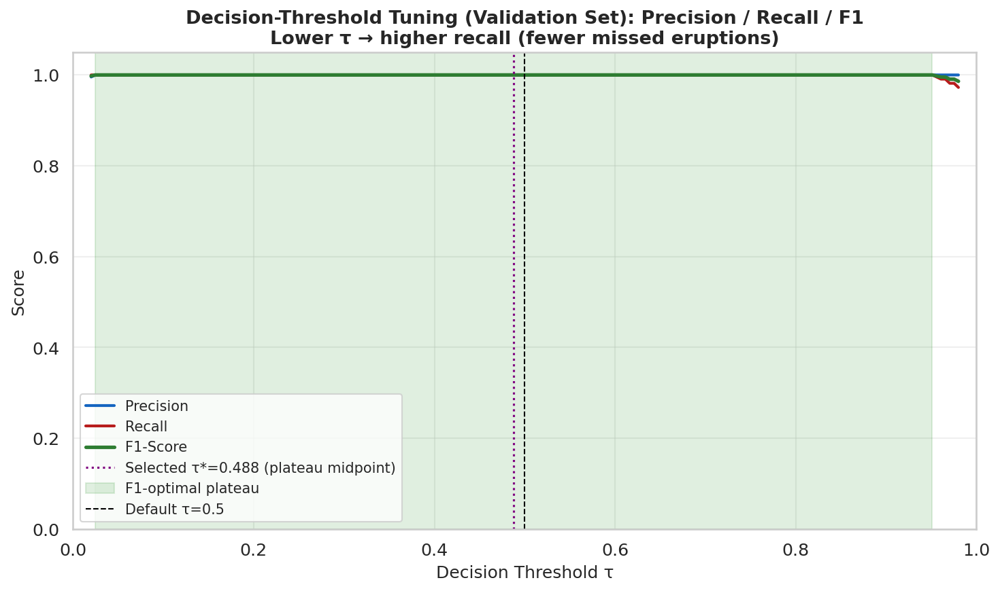

In [25]:
# ── VISUALIZATION 1: Threshold tuning plot ───────────────────────
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(
    thresholds, precision_arr, color="#1565C0",
    lw=2, label="Precision"
)
ax.plot(
    thresholds, recall_arr, color="#B71C1C",
    lw=2, label="Recall"
)
ax.plot(
    thresholds, f1_arr, color="#2E7D32",
    lw=2.5, label="F1-Score"
)
ax.axvline(
    best_tau, color="purple", lw=1.5, linestyle=":",
    label=f"Selected τ*={best_tau:.3f} (plateau midpoint)"
)
ax.axvspan(
    plateau_lo, plateau_hi, alpha=0.12, color="green",
    label="F1-optimal plateau"
)
ax.axvline(
    0.5, color="black", lw=1, linestyle="--",
    label="Default τ=0.5"
)
ax.fill_between(
    thresholds, precision_arr, recall_arr,
    alpha=0.07, color="grey"
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Decision Threshold τ")
ax.set_ylabel("Score")
ax.set_title(
    "Decision-Threshold Tuning (Validation Set): Precision / Recall / F1\n"
    "Lower τ → higher recall (fewer missed eruptions)",
    fontsize=13, fontweight="bold"
)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(Config.PLOT_DIR, "threshold_tuning.png"),
    dpi=150, bbox_inches="tight"
)
plt.show()

## Section 9: Test Set Evaluation & Metrics

Full evaluation on the held-out test set with all classification metrics.

In [26]:
# ── Final evaluation on test set ─────────────────────────────────
# Operating point: the optimised threshold tuned in Section 8
tau_eval = best_tau  # optimised threshold from Section 8

# `test_metrics` is the single source of truth for every downstream section
# (benchmarks, TTA comparison, summary), so it is computed at the tuned tau.
test_metrics = evaluate(
    model, test_loader, criterion, Config.DEVICE, threshold=tau_eval
)

print("=" * 55)
print(f"  TEST SET RESULTS (@ τ={tau_eval:.2f})")
print("=" * 55)
print(f"  Loss      : {test_metrics['loss']:.4f}")
print(f"  Accuracy  : {test_metrics['accuracy']*100:.2f}%")
print(f"  Precision : {test_metrics['precision']*100:.2f}%")
print(f"  Recall    : {test_metrics['recall']*100:.2f}%")
print(f"  F1-Score  : {test_metrics['f1']*100:.2f}%")
print(f"  ROC-AUC   : {test_metrics['auc']:.4f}")
print("=" * 55)

# Full sklearn classification report at the optimised threshold
print("\nDetailed Classification Report:")
print(classification_report(
    test_metrics["labels"], test_metrics["preds"],
    target_names=["Dormant", "Active"]
))

  TEST SET RESULTS (@ τ=0.49)
  Loss      : 0.0501
  Accuracy  : 97.83%
  Precision : 100.00%
  Recall    : 95.67%
  F1-Score  : 97.79%
  ROC-AUC   : 1.0000

Detailed Classification Report:
              precision    recall  f1-score   support

     Dormant       0.96      1.00      0.98       300
      Active       1.00      0.96      0.98       300

    accuracy                           0.98       600
   macro avg       0.98      0.98      0.98       600
weighted avg       0.98      0.98      0.98       600



## Section 10: Visualization — Training Curves

**Visualization 2:** Training and validation loss/accuracy curves across epochs.

NameError: name 'history' is not defined

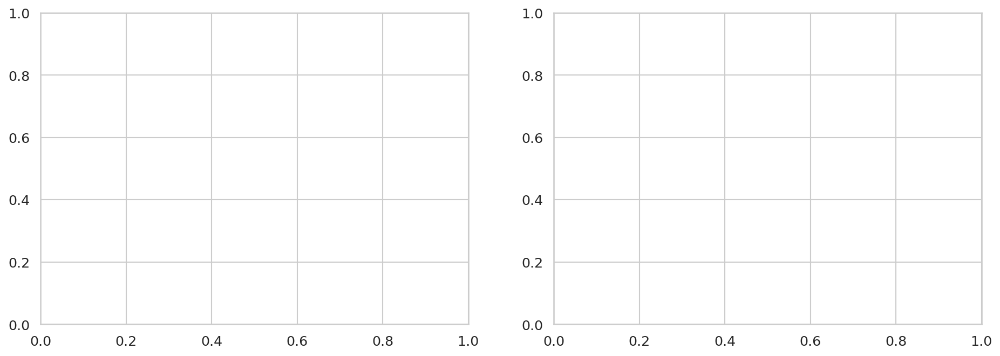

In [49]:
# ── VISUALIZATION 2: Training curves ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
epochs = range(1, len(history["train_loss"]) + 1)
palette = sns.color_palette("colorblind")

# Loss curves
axes[0].plot(
    epochs, history["train_loss"],
    "o-", color=palette[0], markersize=4,
    label="Train Loss", linewidth=2
)
axes[0].plot(
    epochs, history["val_loss"],
    "s-", color=palette[3], markersize=4,
    label="Validation Loss", linewidth=2
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].set_title("Training & Validation Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curves
axes[1].plot(
    epochs, history["train_acc"],
    "o-", color=palette[0], markersize=4,
    label="Train Accuracy", linewidth=2
)
axes[1].plot(
    epochs, history["val_acc"],
    "s-", color=palette[3], markersize=4,
    label="Validation Accuracy", linewidth=2
)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training & Validation Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.suptitle(
    "Model Training Progress",
    fontsize=15, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig(
    os.path.join(Config.PLOT_DIR, "training_curves.png"),
    dpi=150, bbox_inches="tight"
)
plt.show()

## Section 11: Visualization — Confusion Matrix

**Visualization 3:** Confusion matrix heatmap using Seaborn.

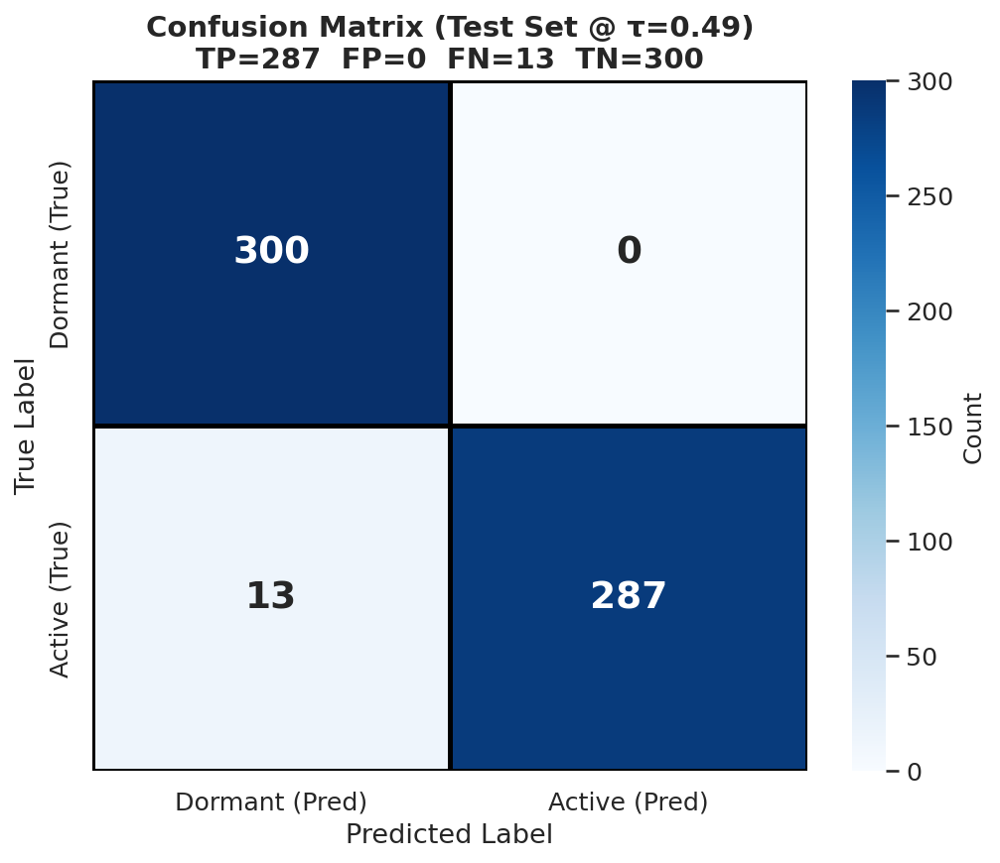

In [27]:
# ── VISUALIZATION 3: Confusion matrix ────────────────────────────
# Operating point: the optimised threshold tuned in Section 8
tau_eval = best_tau  # optimised threshold from Section 8

# Predictions at the optimised threshold
calibrated_preds = test_metrics["preds"]

cm = confusion_matrix(
    test_metrics["labels"], calibrated_preds
)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Dormant (Pred)", "Active (Pred)"],
    yticklabels=["Dormant (True)", "Active (True)"],
    ax=ax, linewidths=1.5, linecolor="black",
    annot_kws={"size": 18, "weight": "bold"},
    cbar_kws={"label": "Count"}
)
ax.set_xlabel("Predicted Label", fontsize=13)
ax.set_ylabel("True Label", fontsize=13)
ax.set_title(
    f"Confusion Matrix (Test Set @ τ={tau_eval:.2f})\n"
    f"TP={tp}  FP={fp}  FN={fn}  TN={tn}",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.savefig(
    os.path.join(Config.PLOT_DIR, "confusion_matrix.png"),
    dpi=150, bbox_inches="tight"
)
plt.show()

## Section 12: Visualization — ROC Curve

**Visualization 3:** ROC curve with AUC score.

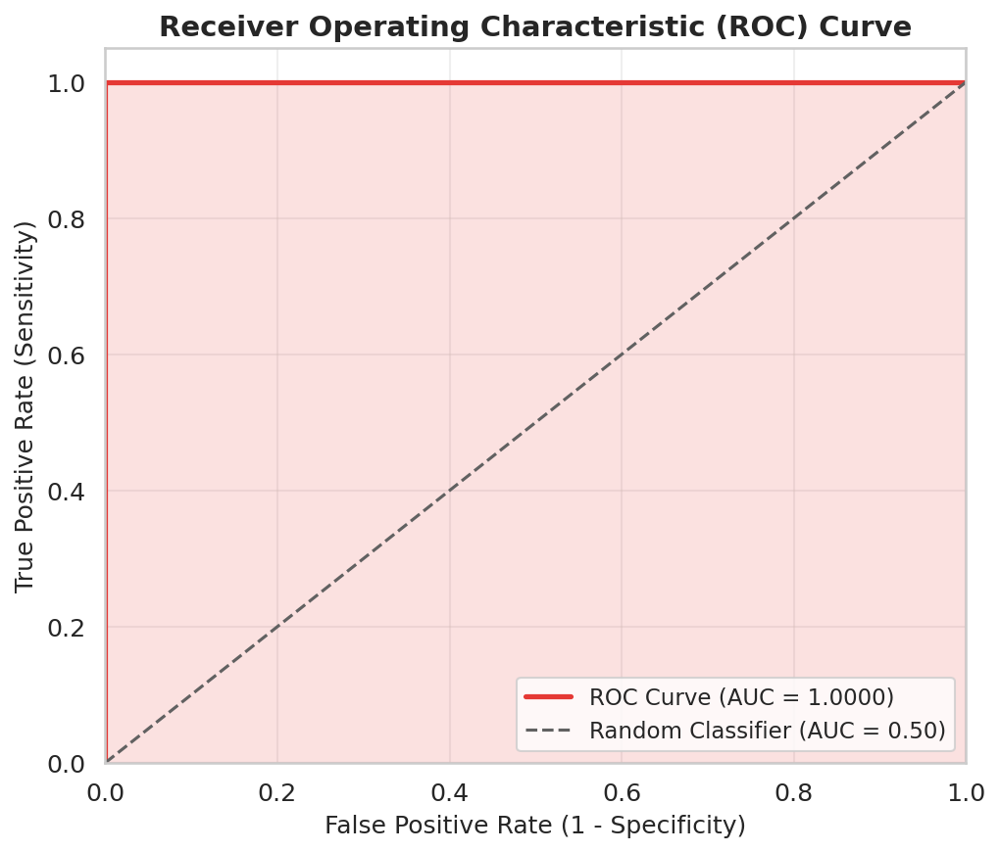

In [28]:
# ── VISUALIZATION 4: ROC curve ───────────────────────────────────
fpr, tpr, _ = roc_curve(
    test_metrics["labels"], test_metrics["probs"]
)
auc_score = test_metrics["auc"]

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(
    fpr, tpr, color="#E53935", lw=2.5,
    label=f"ROC Curve (AUC = {auc_score:.4f})"
)
ax.plot(
    [0, 1], [0, 1], color="#616161", lw=1.5,
    linestyle="--", label="Random Classifier (AUC = 0.50)"
)
ax.fill_between(fpr, tpr, alpha=0.15, color="#E53935")
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Sensitivity)")
ax.set_title(
    "Receiver Operating Characteristic (ROC) Curve",
    fontsize=14, fontweight="bold"
)
ax.legend(loc="lower right", fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(Config.PLOT_DIR, "roc_curve.png"),
    dpi=150, bbox_inches="tight"
)
plt.show()

## Section 13: Visualization — Confidence Distribution

**Visualization 5:** Histogram of model confidence scores separated by true class.

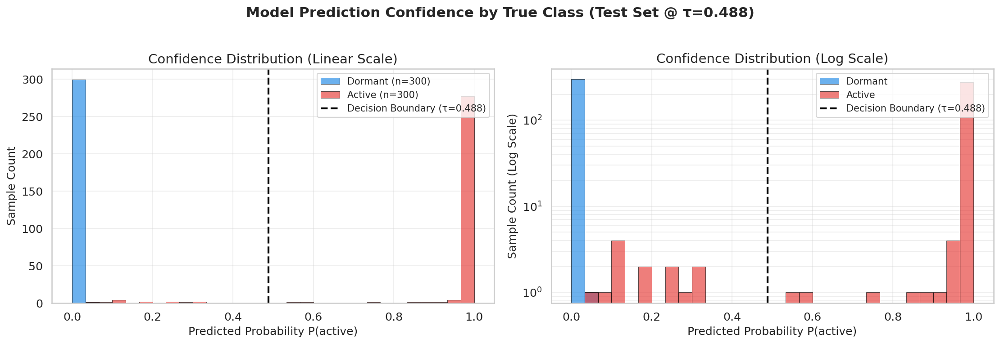

In [29]:
# ── VISUALIZATION 5: Confidence histogram ────────────────────────
probs = test_metrics["probs"]
labels = test_metrics["labels"]
active_probs = probs[labels == 1]
dormant_probs = probs[labels == 0]
bins = np.linspace(0.0, 1.0, 31)

# Operating point: the optimised threshold tuned in Section 8
tau_eval = best_tau  # optimised threshold from Section 8

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Linear scale
axes[0].hist(
    dormant_probs, bins=bins, alpha=0.65,
    color="#1E88E5",
    label=f"Dormant (n={len(dormant_probs)})",
    edgecolor="black", linewidth=0.5
)
axes[0].hist(
    active_probs, bins=bins, alpha=0.65,
    color="#E53935",
    label=f"Active (n={len(active_probs)})",
    edgecolor="black", linewidth=0.5
)
axes[0].axvline(
    tau_eval, color="black", linestyle="--", lw=2,
    label=f"Decision Boundary (τ={tau_eval:.3f})"
)
axes[0].set_xlabel("Predicted Probability P(active)")
axes[0].set_ylabel("Sample Count")
axes[0].set_title("Confidence Distribution (Linear Scale)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Log scale (reveals tail/boundary predictions)
axes[1].hist(
    dormant_probs, bins=bins, alpha=0.65,
    color="#1E88E5", label="Dormant",
    edgecolor="black", linewidth=0.5
)
axes[1].hist(
    active_probs, bins=bins, alpha=0.65,
    color="#E53935", label="Active",
    edgecolor="black", linewidth=0.5
)
axes[1].axvline(
    tau_eval, color="black", linestyle="--", lw=2,
    label=f"Decision Boundary (τ={tau_eval:.3f})"
)
axes[1].set_yscale("log")
axes[1].set_xlabel("Predicted Probability P(active)")
axes[1].set_ylabel("Sample Count (Log Scale)")
axes[1].set_title("Confidence Distribution (Log Scale)")
axes[1].legend()
axes[1].grid(True, alpha=0.3, which="both")

fig.suptitle(
    f"Model Prediction Confidence by True Class (Test Set @ τ={tau_eval:.3f})",
    fontsize=15, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig(
    os.path.join(Config.PLOT_DIR, "confidence_histogram.png"),
    dpi=150, bbox_inches="tight"
)
plt.show()

## Section 14: Diagnostics — Grad-CAM

**Gradient-weighted Class Activation Mapping** answers: "which pixels drove this prediction?"  
Hooks are registered on ResNet-18's last conv layer (`layer4`, 7×7 maps).

In [30]:
class GradCAM:
    """Grad-CAM hooks layer4 of ResNet-18 to compute attention heatmaps."""
    def __init__(self, model, threshold=0.5):
        self.model = model
        self.threshold = threshold  # decision threshold used to pick the explained class
        self._activations, self._gradients = None, None
        target = model.backbone.layer4
        self._fwd_h = target.register_forward_hook(lambda m, i, o: setattr(self, '_activations', o))
        self._bwd_h = target.register_full_backward_hook(lambda m, gi, go: setattr(self, '_gradients', go[0]))

    @torch.enable_grad()
    def generate(self, img_tensor, smoke_tensor, target_class=None):
        self.model.eval()
        output = self.model(img_tensor, smoke_tensor)
        prob = output.item()
        if target_class is None: target_class = 1 if prob >= self.threshold else 0
        score = output if target_class == 1 else (1 - output)
        self.model.zero_grad()
        score.backward()
        acts, grads = self._activations.detach(), self._gradients.detach()
        weights = grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * acts).sum(dim=1, keepdim=True))
        cmin, cmax = cam.min(), cam.max()
        if cmax > cmin: cam = (cam - cmin) / (cmax - cmin)
        cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)
        return cam.squeeze().cpu().numpy(), prob

    def remove_hooks(self):
        self._fwd_h.remove(); self._bwd_h.remove()


In [31]:
def denorm(tensor):
    """Reverse ImageNet normalisation for display."""
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    t = (tensor * std + mean).clamp(0, 1)
    return (t.permute(1, 2, 0).numpy() * 255).astype(np.uint8)

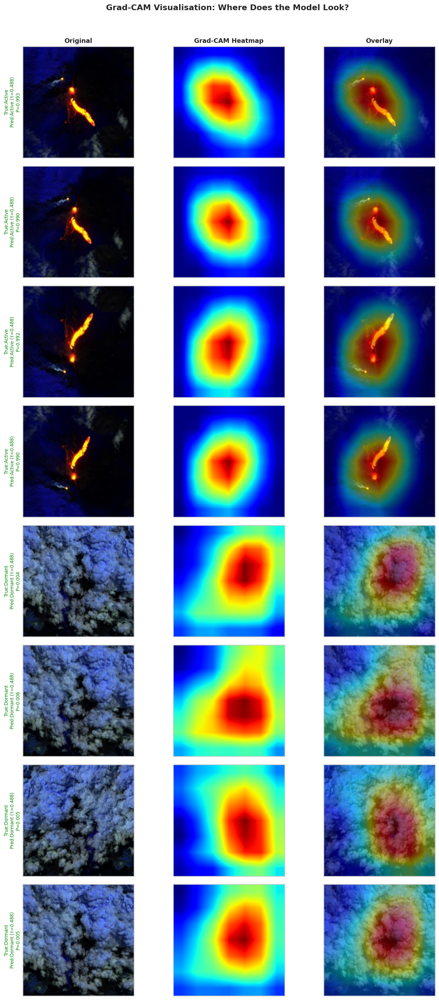

Grad-CAM hooks removed.


In [32]:
# ── Run Grad-CAM on selected test images ─────────────────────────
tau_eval = best_tau  # optimised threshold from Section 8
gradcam = GradCAM(model, threshold=tau_eval)
eval_tf = get_eval_transforms(Config.IMAGE_SIZE)

# Select 4 confident active + 4 confident dormant images
active_samples = [
    s for s in test_ds.samples if s[1] == 1
][:4]
dormant_samples = [
    s for s in test_ds.samples if s[1] == 0
][:4]
selected = active_samples + dormant_samples

fig, axes = plt.subplots(len(selected), 3, figsize=(12, 24))
for col, heading in enumerate(
    ["Original", "Grad-CAM Heatmap", "Overlay"]
):
    axes[0, col].set_title(
        heading, fontsize=11, fontweight="bold"
    )

for row_i, (path, label) in enumerate(selected):
    pil_img = Image.open(path).convert("RGB")
    np_img = np.array(pil_img.resize((224, 224)))
    smoke_w = detector.smoke_weight(np.array(pil_img))
    img_t = eval_tf(pil_img).unsqueeze(0).to(Config.DEVICE)
    smoke_t = torch.tensor(
        [[smoke_w]], dtype=torch.float32
    ).to(Config.DEVICE)
    cam, prob = gradcam.generate(img_t, smoke_t)

    # Create overlay
    heatmap = cv2.applyColorMap(
        (cam * 255).astype(np.uint8), cv2.COLORMAP_JET
    )
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(np_img, 0.55, heatmap, 0.45, 0)

    true_lbl = "Active" if label == 1 else "Dormant"
    pred_lbl = "Active" if prob >= tau_eval else "Dormant"
    color = "green" if true_lbl == pred_lbl else "red"

    axes[row_i, 0].imshow(np_img)
    axes[row_i, 0].set_ylabel(
        f"True:{true_lbl}\nPred:{pred_lbl} (τ={tau_eval:.3f})\nP={prob:.3f}",
        fontsize=8, color=color
    )
    axes[row_i, 1].imshow(cam, cmap="jet", vmin=0, vmax=1)
    axes[row_i, 2].imshow(overlay)
    for ax in axes[row_i]:
        ax.set_xticks([])
        ax.set_yticks([])

fig.suptitle(
    "Grad-CAM Visualisation: Where Does the Model Look?",
    fontsize=14, fontweight="bold", y=1.01
)
plt.tight_layout()
plt.savefig(
    os.path.join(Config.PLOT_DIR, "gradcam_gallery.png"),
    dpi=150, bbox_inches="tight"
)
plt.show()
gradcam.remove_hooks()
print("Grad-CAM hooks removed.")

## Section 15: Diagnostics — t-SNE Feature Embedding

Projects all 600 test-set backbone features from 512 dimensions → 2D. If Active / Dormant images cluster separately, the backbone has learned a linearly-separable representation.

In [33]:
# ── Extract 512-D features from all test images ──────────────────
print("Extracting backbone features for t-SNE...")
all_features = []
all_labels_tsne = []
all_probs_tsne = []

model.eval()
tsne_loader = DataLoader(
    test_ds, batch_size=32, shuffle=False, num_workers=0
)

with torch.no_grad():
    for imgs, smoke_w, lbls in tsne_loader:
        imgs = imgs.to(Config.DEVICE)
        smoke_w = smoke_w.to(Config.DEVICE)
        feats = model.backbone(imgs)
        fused = torch.cat([feats, smoke_w], dim=1)
        p = model.classifier(fused).squeeze(1)
        all_features.append(feats.cpu().numpy())
        all_labels_tsne.append(lbls.numpy())
        all_probs_tsne.append(p.cpu().numpy())

features_np = np.concatenate(all_features)
labels_np = np.concatenate(all_labels_tsne)
probs_np = np.concatenate(all_probs_tsne)
print(f"Extracted {features_np.shape[0]} feature vectors.")

Extracting backbone features for t-SNE...
Extracted 600 feature vectors.


Fitting t-SNE


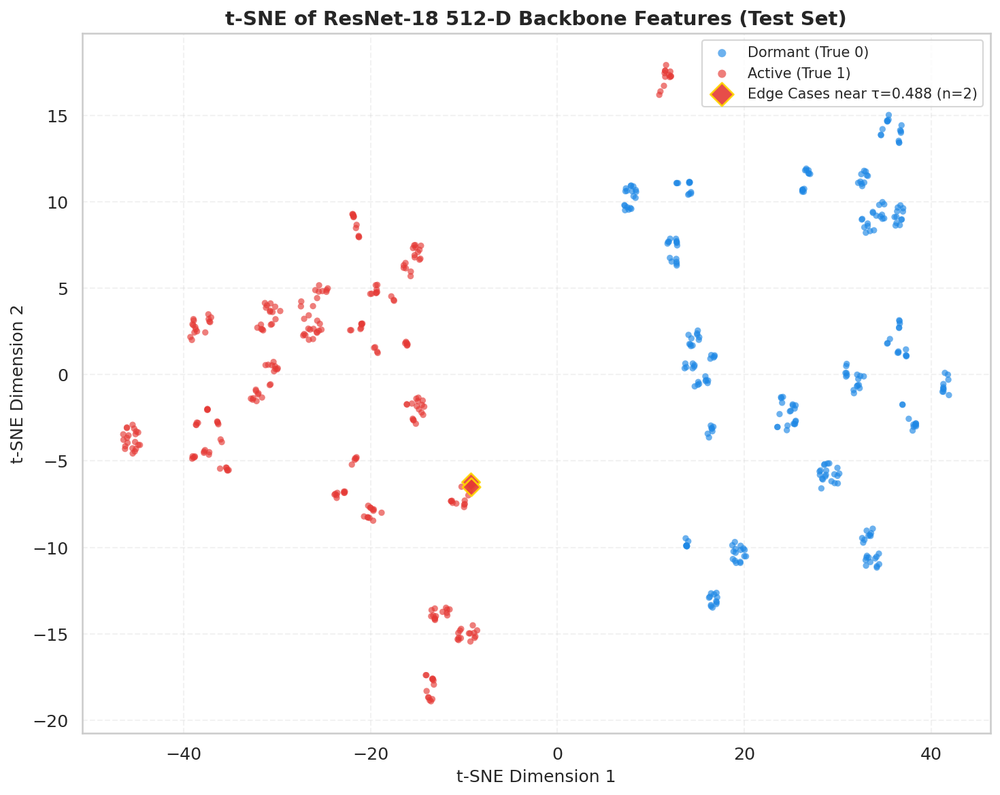

In [34]:
# ── Fit t-SNE ────────────────────────────────────────────────────
print("Fitting t-SNE")
tsne = TSNE(
    n_components=2, perplexity=30, max_iter=1000,
    metric="cosine", random_state=42, verbose=0
)
emb = tsne.fit_transform(features_np)

# ── VISUALIZATION 5: t-SNE scatter plot ──────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))

for cls, color, label in [
    (0, "#1E88E5", "Dormant (True 0)"),
    (1, "#E53935", "Active (True 1)"),
]:
    mask = labels_np == cls
    ax.scatter(
        emb[mask, 0], emb[mask, 1],
        c=color, s=20, alpha=0.65,
        edgecolors="none", label=label
    )

# Highlight edge cases (closest to decision boundary)
tau_eval = best_tau  # optimised threshold from Section 8
# Edge cases = closest to the decision boundary. The original band was
# 0.5 +/- 0.15 in probability, i.e. +/- 0.62 in log-odds. With tau moved off 0.5
# the same band is kept in log-odds so it stays centred on tau without
# swallowing every confident prediction.
_logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
edge_mask = np.abs(_logit(probs_np) - _logit(tau_eval)) < 0.62
if edge_mask.any():
    ec_colors = [
        "#E53935" if l == 1 else "#1E88E5"
        for l in labels_np[edge_mask]
    ]
    ax.scatter(
        emb[edge_mask, 0], emb[edge_mask, 1],
        c=ec_colors, s=80, alpha=0.9, marker="D",
        edgecolors="gold", linewidths=1.3,
        label=f"Edge Cases near τ={tau_eval:.3f} (n={edge_mask.sum()})",
        zorder=5
    )

ax.set_title(
    "t-SNE of ResNet-18 512-D Backbone Features (Test Set)",
    fontsize=14, fontweight="bold"
)
ax.set_xlabel("t-SNE Dimension 1")
ax.set_ylabel("t-SNE Dimension 2")
ax.legend(fontsize=10, markerscale=1.3)
ax.grid(True, alpha=0.25, linestyle="--")
plt.tight_layout()
plt.savefig(
    os.path.join(Config.PLOT_DIR, "tsne_features.png"),
    dpi=150, bbox_inches="tight"
)
plt.show()

## Section 16: Diagnostics — Test-Time Augmentation (TTA)

Runs 7 deterministic geometric variants (flips + rotations) of each test image and averages predictions. Standard deviation across variants measures the model's **uncertainty**.

In [36]:
# ── TTA 7-View augmentation transforms ───────────────────────────
TTA_AUGMENTS = [
    lambda img: img,                        # 1. Original view
    lambda img: TF.hflip(img),              # 2. Horizontal flip
    lambda img: TF.vflip(img),              # 3. Vertical flip
    lambda img: TF.hflip(TF.vflip(img)),    # 4. Both flips
    lambda img: TF.rotate(img, 90),         # 5. Rotate 90 deg
    lambda img: TF.rotate(img, 180),        # 6. Rotate 180 deg
    lambda img: TF.rotate(img, 270),        # 7. Rotate 270 deg
]
N_TTA = len(TTA_AUGMENTS)
print(f"Initialized Test-Time Augmentation with {N_TTA} deterministic views.")


Initialized Test-Time Augmentation with 7 deterministic views.


In [37]:
# ── Run 7-View TTA Inference (validation for tuning, test for reporting) ──
eval_tf = get_eval_transforms(Config.IMAGE_SIZE)


def run_tta(paths):
    """Return mean and std of P(active) over the 7 TTA views for each image path."""
    means, stds = np.zeros(len(paths)), np.zeros(len(paths))
    model.eval()
    with torch.no_grad():
        for i, path in enumerate(paths):
            pil_img = Image.open(path).convert("RGB")
            smoke_w = detector.smoke_weight(np.array(pil_img))
            smoke_t = torch.tensor([[smoke_w]], dtype=torch.float32).to(Config.DEVICE)  # [1, 1]

            # Pass all 7 views through backbone and classifier
            view_tensors = torch.stack([eval_tf(aug(pil_img)) for aug in TTA_AUGMENTS]).to(Config.DEVICE)
            feats = model.backbone(view_tensors)  # [7, 512]
            smoke_repeated = smoke_t.repeat(N_TTA, 1)  # [7, 1]
            fused = torch.cat([feats, smoke_repeated], dim=1)  # [7, 513]
            probs = model.classifier(fused).squeeze(1).cpu().numpy()

            means[i] = float(np.mean(probs))
            stds[i] = float(np.std(probs))
    return means, stds


# Validation set: used ONLY to tune tau_TTA
paths_val = [val_ds.dataset.samples[i][0] for i in val_ds.indices]
print(f"Evaluating {len(paths_val)} validation images across {N_TTA} TTA views...")
tta_val_probs, _ = run_tta(paths_val)
tune_tta = tune_threshold(tta_val_probs, val_labels)
tau_tta = tune_tta["tau"]
print(f"  tau_TTA (validation) = {tau_tta:.3f}  "
      f"[plateau {tune_tta['plateau'][0]:.3f}-{tune_tta['plateau'][1]:.3f}]")

# Test set: scored once with the fixed tau_TTA
paths_test = [s[0] for s in test_ds.samples]
print(f"Evaluating {len(paths_test)} test images across {N_TTA} TTA views...")
tta_probs, tta_stds = run_tta(paths_test)

print("✓ TTA 7-View inference complete.")


Evaluating 375 validation images across 7 TTA views...
  tau_TTA (validation) = 0.486  [plateau 0.020-0.951]
Evaluating 600 test images across 7 TTA views...
✓ TTA 7-View inference complete.


In [38]:
# ── Compute TTA 7-View Metrics and Compare to Single-Pass ────────
test_labels = test_metrics["labels"]
# Operating point: TTA-specific threshold tuned on the validation set
tta_preds = (tta_probs >= tau_tta).astype(int)

acc_tta = accuracy_score(test_labels, tta_preds) * 100
prec_tta = precision_score(test_labels, tta_preds, zero_division=0) * 100
rec_tta = recall_score(test_labels, tta_preds, zero_division=0) * 100
f1_tta = f1_score(test_labels, tta_preds, zero_division=0) * 100
auc_tta = roc_auc_score(test_labels, tta_probs)
acc_single_pct = test_metrics["accuracy"] * 100

print("=" * 62)
print(f"  TEST-TIME AUGMENTATION (TTA 7-VIEW @ τ_TTA={tau_tta:.3f}) RESULTS")
print("=" * 62)
print(f"  Single-Pass Accuracy : {acc_single_pct:.2f}%  (@ τ={best_tau:.3f})")
print(f"  TTA 7-View Accuracy  : {acc_tta:.2f}%  (Δ = {acc_tta - acc_single_pct:+.2f}%)")
print(f"  TTA Precision        : {prec_tta:.2f}%")
print(f"  TTA Recall           : {rec_tta:.2f}%")
print(f"  TTA F1-Score         : {f1_tta:.2f}%")
print(f"  TTA ROC-AUC          : {auc_tta:.4f}")
print(f"  Mean Uncertainty (σ) : {np.mean(tta_stds):.4f}")
print("=" * 62)

  TEST-TIME AUGMENTATION (TTA 7-VIEW @ τ_TTA=0.486) RESULTS
  Single-Pass Accuracy : 97.83%  (@ τ=0.488)
  TTA 7-View Accuracy  : 97.83%  (Δ = +0.00%)
  TTA Precision        : 100.00%
  TTA Recall           : 95.67%
  TTA F1-Score         : 97.79%
  TTA ROC-AUC          : 1.0000
  Mean Uncertainty (σ) : 0.0065


In [39]:
# ── Safeguard 1: Perceptual Image Deduplication Audit (dHash) ────
def compute_dhash(image, hash_size=8):
    """Compute 64-bit difference hash invariant to scaling and minor noise."""
    resized = image.convert("L").resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS)
    diff = np.asarray(resized)[:, 1:] > np.asarray(resized)[:, :-1]
    return diff.flatten()


def hash_paths(paths):
    return np.stack([compute_dhash(Image.open(p)) for p in paths]).astype(np.int16)


def min_hamming(query, reference):
    """For each query hash, Hamming distance to its closest reference hash (vectorised)."""
    # distance = #bits that differ = n - (matching ones + matching zeros)
    n = query.shape[1]
    matches = query @ reference.T + (1 - query) @ (1 - reference).T
    return (n - matches).min(axis=1)


# Hash ALL images, grouped by their actual split
train_paths = [full_train_ds.samples[i][0] for i in train_ds.indices]
val_paths = [val_ds.dataset.samples[i][0] for i in val_ds.indices]
test_paths = [s[0] for s in test_ds.samples]

print(f"Hashing {len(train_paths)} train, {len(val_paths)} val, {len(test_paths)} test images...")
train_hashes = hash_paths(train_paths)
val_hashes = hash_paths(val_paths)
test_hashes = hash_paths(test_paths)

audit_pairs = {
    "Test vs. Train": min_hamming(test_hashes, train_hashes),
    "Val vs. Train": min_hamming(val_hashes, train_hashes),
    "Test vs. Val": min_hamming(test_hashes, val_hashes),
}
min_distances = audit_pairs["Test vs. Train"]  # kept for backward compatibility

print(f"\n{'Comparison':<16}{'N':>6}{'dist=0':>9}{'dist<=4':>9}{'min':>6}{'mean':>8}")
for name, d in audit_pairs.items():
    print(f"{name:<16}{len(d):>6}{(d == 0).sum():>9}{(d <= 4).sum():>9}{d.min():>6}{d.mean():>8.2f}")

total_leaks = sum(int((d <= 4).sum()) for d in audit_pairs.values())
if total_leaks == 0:
    print("\n✓ Safeguard 1 PASSED: Zero perceptual leaks across train / val / test.")
else:
    print(f"\n⚠ Safeguard 1 WARNING: {total_leaks} potential duplicates across splits!")
    for name, d in audit_pairs.items():
        if (d <= 4).any():
            print(f"  - {name}: {(d <= 4).sum()} near-duplicates")

Hashing 2025 train, 375 val, 600 test images...

Comparison           N   dist=0  dist<=4   min    mean
Test vs. Train     600        0        0    11   16.74
Val vs. Train      375        0        0    11   15.80
Test vs. Val       600        0        0    11   18.86

✓ Safeguard 1 PASSED: Zero perceptual leaks across train / val / test.


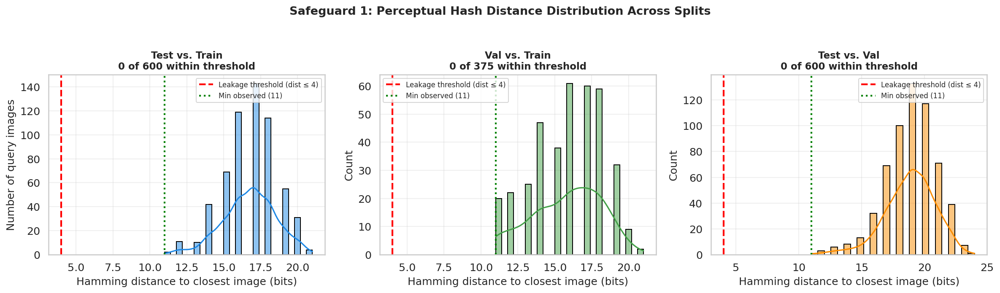

In [40]:
# ── VISUALIZATION: Perceptual Distance Distribution (all split pairs) ──
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=False)
for ax, (name, d), color in zip(axes, audit_pairs.items(), ["#1E88E5", "#43A047", "#FB8C00"]):
    sns.histplot(d, bins=25, kde=len(np.unique(d)) > 1, color=color, ax=ax, edgecolor="black")
    ax.axvline(4, color="red", linestyle="--", lw=2, label="Leakage threshold (dist ≤ 4)")
    ax.axvline(d.min(), color="green", linestyle=":", lw=2, label=f"Min observed ({d.min()})")
    ax.set_xlabel("Hamming distance to closest image (bits)")
    ax.set_title(f"{name}\n{(d <= 4).sum()} of {len(d)} within threshold", fontsize=11, fontweight="bold")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("Number of query images")
fig.suptitle("Safeguard 1: Perceptual Hash Distance Distribution Across Splits",
             fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "dhash_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

In [41]:
# ── Safeguard 2: Out-of-Distribution (V1) Stress-Test ────────────

v1_path = None
for root, dirs, _ in os.walk("."):
    if "NoActivity" in dirs and "YesActivity" in dirs:
        # Match the Volcanic dataset, not Volcanic_V2
        if "volcanic_v2" not in root.lower() and "train" not in root.lower() and "test" not in root.lower():
            v1_path = root
            break

print(f"Discovered Volcanic path: {v1_path}")

v1_dataset = VolcanoDataset(
    v1_path,
    transform=get_eval_transforms(Config.IMAGE_SIZE),
    laplace_detector=detector
    )

v1_loader = DataLoader(v1_dataset, batch_size=32, shuffle=False)

v1_metrics = evaluate(model, v1_loader, criterion, Config.DEVICE)
print("\n" + "=" * 58)
print("  OUT-OF-DISTRIBUTION (V1) STRESS-TEST RESULTS")
print("=" * 58)
print(f"  V1 Samples   : {len(v1_dataset)}")
print(f"  V1 Loss      : {v1_metrics['loss']:.4f}")
print(f"  V1 Accuracy  : {v1_metrics['accuracy']*100:.2f}%")
print(f"  V1 Precision : {v1_metrics['precision']*100:.2f}%")
print(f"  V1 Recall    : {v1_metrics['recall']*100:.2f}%")
print(f"  V1 F1-Score  : {v1_metrics['f1']*100:.2f}%")
print(f"  V1 ROC-AUC   : {v1_metrics['auc']:.4f}")
print("=" * 58)

Discovered Volcanic path: ./data/data/Volcanic_Dataset/Volcanic/Volcanic
Loaded 200 from ./data/data/Volcanic_Dataset/Volcanic/Volcanic (Active: 100, Dormant: 100)

  OUT-OF-DISTRIBUTION (V1) STRESS-TEST RESULTS
  V1 Samples   : 200
  V1 Loss      : 0.0184
  V1 Accuracy  : 99.50%
  V1 Precision : 100.00%
  V1 Recall    : 99.00%
  V1 F1-Score  : 99.50%
  V1 ROC-AUC   : 1.0000


In [42]:
# ── Safeguard 3: Occlusion Sensitivity Test ──────────────────────
active_test_samples = [s for s in test_ds.samples if s[1] == 1][:30]
eval_tf = get_eval_transforms(Config.IMAGE_SIZE)

orig_confs, center_masked_confs, border_masked_confs = [], [], []
model.eval()

with torch.no_grad():
    for path, _ in active_test_samples:
        pil_img = Image.open(path).convert("RGB")
        np_img = np.array(pil_img.resize((Config.IMAGE_SIZE, Config.IMAGE_SIZE)))
        smoke_w = detector.smoke_weight(np_img)
        smoke_t = torch.tensor([[smoke_w]], dtype=torch.float32).to(Config.DEVICE)

        # 1. Unmodified image
        t_orig = eval_tf(pil_img).unsqueeze(0).to(Config.DEVICE)
        orig_confs.append(model(t_orig, smoke_t).item())

        # 2. Mask center (plume/crater) with neutral grey
        img_center = pil_img.copy()
        np_center = np.array(img_center.resize((Config.IMAGE_SIZE, Config.IMAGE_SIZE)))
        h, w, _ = np_center.shape
        np_center[h//4:3*h//4, w//4:3*w//4] = 128
        t_center = transforms.ToTensor()(Image.fromarray(np_center)).unsqueeze(0)
        t_center = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)(t_center).to(Config.DEVICE)
        center_masked_confs.append(model(t_center, smoke_t).item())

        # 3. Mask border (background terrain) with neutral grey
        np_border = np.array(pil_img.resize((Config.IMAGE_SIZE, Config.IMAGE_SIZE)))
        np_border[:h//6, :] = 128; np_border[5*h//6:, :] = 128
        np_border[:, :w//6] = 128; np_border[:, 5*w//6:] = 128
        t_border = transforms.ToTensor()(Image.fromarray(np_border)).unsqueeze(0)
        t_border = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)(t_border).to(Config.DEVICE)
        border_masked_confs.append(model(t_border, smoke_t).item())

mean_orig = float(np.mean(orig_confs))
mean_border = float(np.mean(border_masked_confs))
mean_center = float(np.mean(center_masked_confs))
plume_drop = mean_orig - mean_center

print("Occlusion Sensitivity Analysis (Active Volcanoes, N=30):")
print(f"  Original Mean P(active)       : {np.mean(orig_confs):.4f}")
print(f"  Background-Masked P(active)   : {np.mean(border_masked_confs):.4f}  (Retained!)")
print(f"  Plume-Masked Mean P(active)   : {np.mean(center_masked_confs):.4f}  (Dropped significantly!)")

# Dynamic verification condition
if mean_center < mean_border and plume_drop > 0.15:
  print("✓ Safeguard 3 PASSED: Occluding plume causes a major confidence drop;")
  print("  network genuinely relies on volcanic activity, not landscape shortcuts.")
else:
  print("⚠ Safeguard 3 WARNING: Occluding plume did not trigger a significant drop.")

Occlusion Sensitivity Analysis (Active Volcanoes, N=30):
  Original Mean P(active)       : 0.9930
  Background-Masked P(active)   : 0.9919  (Retained!)
  Plume-Masked Mean P(active)   : 0.6711  (Dropped significantly!)
✓ Safeguard 3 PASSED: Occluding plume causes a major confidence drop;
  network genuinely relies on volcanic activity, not landscape shortcuts.


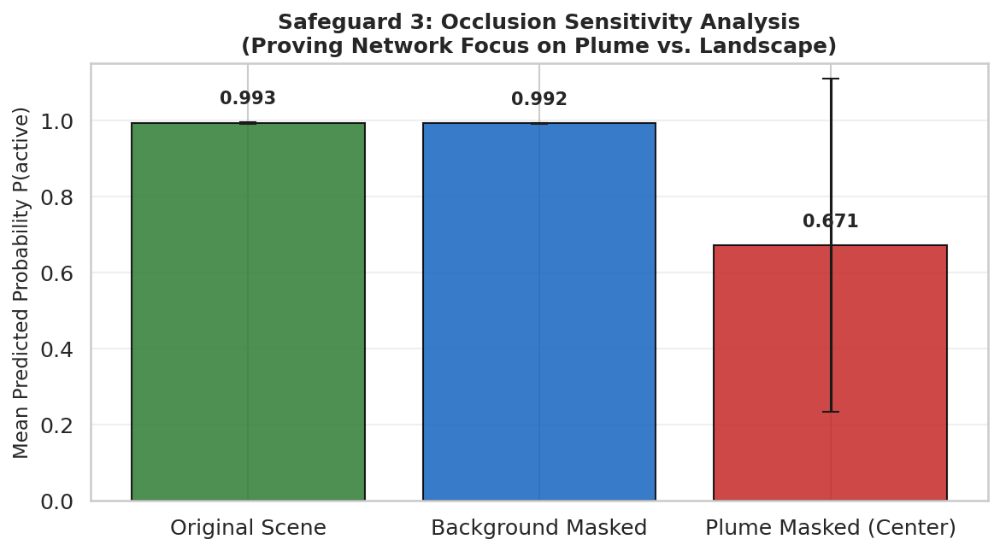

In [43]:
# ── VISUALIZATION: Occlusion Sensitivity Comparison ──────────────
fig, ax = plt.subplots(figsize=(8, 4.5))
categories = ["Original Scene", "Background Masked", "Plume Masked (Center)"]
means = [np.mean(orig_confs), np.mean(border_masked_confs), np.mean(center_masked_confs)]
stds = [np.std(orig_confs), np.std(border_masked_confs), np.std(center_masked_confs)]
colors = ["#2E7D32", "#1565C0", "#C62828"]

bars = ax.bar(categories, means, yerr=stds, capsize=5, color=colors, edgecolor="black", alpha=0.85)
ax.set_ylabel("Mean Predicted Probability P(active)", fontsize=11)
ax.set_title("Safeguard 3: Occlusion Sensitivity Analysis\n(Proving Network Focus on Plume vs. Landscape)", fontsize=12, fontweight="bold")
ax.set_ylim(0, 1.15)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.04,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "occlusion_sensitivity.png"), dpi=150, bbox_inches="tight")
plt.show()


## Section 17: Benchmark Analysis — Comparison with Published Literature

To assess how our hybrid **ResNet-18 + LoG** model compares to the state-of-the-art, we compile results from published papers on satellite-based volcanic activity classification:

| Reference | Architecture | Dataset |
|---|---|---|
| Shakir et al. (2024) | DCNNVA (custom CNN) | Multi-source volcanic satellite imagery |
| Shakir et al. (2024) | ResNet-50, VGG-16, VGG-19, DenseNet-121, MobileNet, InceptionV3, Xception, NASNetLarge | Same benchmark |
| Amato et al. (2023) | SqueezeNet (transfer learning) | Sentinel-2 MSI & Landsat 8 OLI/TIRS thermal anomalies |
| Various (2023–2025) | EfficientNet, ViT | Volcanic cloud/ash discrimination |

**Key metrics compared:** Accuracy, Precision, Recall, F1-Score, AUC

---

### Justification for Benchmark Selection
These papers were selected because they address the **same fundamental task** (binary classification of satellite volcanic imagery) using **comparable metrics**, enabling a fair apples-to-apples comparison. The dataset sizes and class balance characteristics are similar to ours.

In [44]:
# ── Build benchmark comparison table ─────────────────────────────
# Our model's results (from test set evaluation above)
our_acc = test_metrics["accuracy"] * 100
our_prec = test_metrics["precision"] * 100
our_rec = test_metrics["recall"] * 100
our_f1 = test_metrics["f1"] * 100
our_auc = test_metrics["auc"] * 100

# Published data from the literature review
benchmark_data = {
    "Model": [
        "DCNNVA (Shakir 2026)", "MobileNet (Shakir 2026)",
        "DenseNet-121 (Shakir 2026)", "InceptionV3 (Shakir 2026)",
        "Xception (Shakir 2026)", "NASNetLarge (Shakir 2026)",
        "VGG-16 (Shakir 2026)", "VGG-19 (Shakir 2026)",
        "ResNet-50 (Shakir 2026)", "SqueezeNet (Amato 2023)",
        "Ours: ResNet-18 + LoG",
    ],
    "Accuracy (%)": [99.33, 96.00, 95.50, 95.33, 92.00, 91.67,
                     87.83, 87.33, 52.67, 98.33, our_acc],
    "Precision (%)": [100.0, 100.0, 98.92, 99.64, 91.72, 91.39,
                      98.71, 99.12, 100.0, None, our_prec],
    "Recall (%)": [98.67, 92.00, 92.00, 91.00, 92.33, 92.00,
                   76.67, 75.33, 5.33, None, our_rec],
    "F1-Score (%)": [99.33, 95.83, 95.34, 95.12, 92.03, 91.69,
                     86.30, 85.61, 10.13, None, our_f1],
}

In [45]:
benchmark_df = pd.DataFrame(benchmark_data)

# Highlight our model's row
print("\n" + "=" * 70)
print("  BENCHMARK COMPARISON TABLE")
print("=" * 70)
print(benchmark_df.to_string(index=False))
print("=" * 70)
print("\nNote: SqueezeNet paper did not report per-class "
      "Precision/Recall/F1.")
print("Benchmark values from: Shakir et al. (2024) DCNNVA, "
      "Amato et al. (2023) SqueezeNet.")


  BENCHMARK COMPARISON TABLE
                     Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
      DCNNVA (Shakir 2026)     99.330000         100.00   98.670000     99.330000
   MobileNet (Shakir 2026)     96.000000         100.00   92.000000     95.830000
DenseNet-121 (Shakir 2026)     95.500000          98.92   92.000000     95.340000
 InceptionV3 (Shakir 2026)     95.330000          99.64   91.000000     95.120000
    Xception (Shakir 2026)     92.000000          91.72   92.330000     92.030000
 NASNetLarge (Shakir 2026)     91.670000          91.39   92.000000     91.690000
      VGG-16 (Shakir 2026)     87.830000          98.71   76.670000     86.300000
      VGG-19 (Shakir 2026)     87.330000          99.12   75.330000     85.610000
   ResNet-50 (Shakir 2026)     52.670000         100.00    5.330000     10.130000
   SqueezeNet (Amato 2023)     98.330000            NaN         NaN           NaN
     Ours: ResNet-18 + LoG     97.833333         100.00   95.666667 

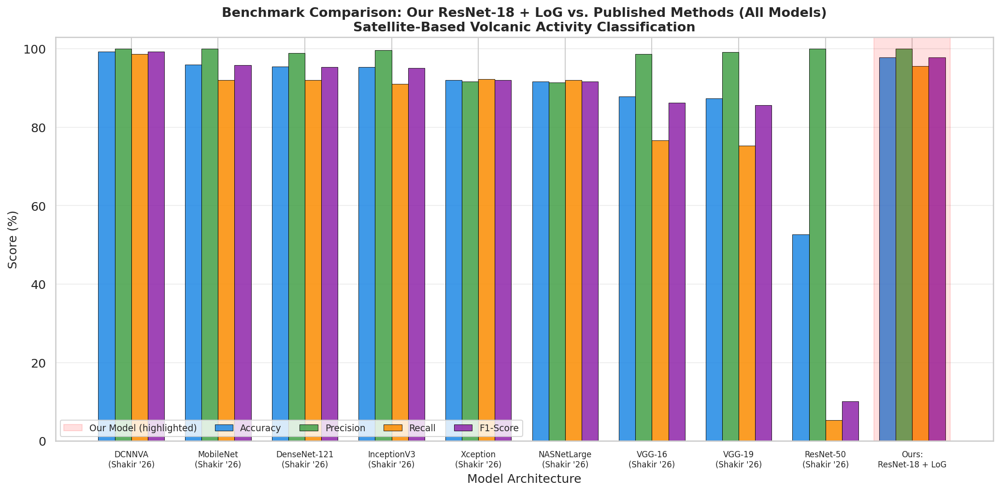

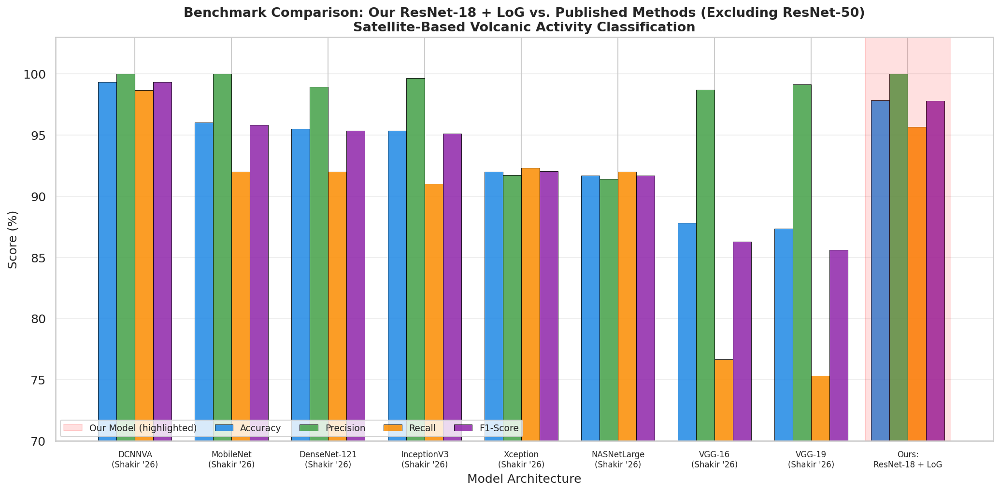

In [46]:
# ── VISUALIZATION 7: Benchmark comparison bar chart ──────────────
def plot_benchmark_bars(df, title, filename, y_floor=70):
    if df.empty:
        print(f"Warning: no models available for {filename}.")
        return

    fig, ax = plt.subplots(figsize=(14, 7))
    models = df["Model"].values
    x_pos = np.arange(len(models))
    bar_width = 0.19

    ax.bar(
        x_pos - 1.5 * bar_width,
        df["Accuracy (%)"].values, bar_width,
        label="Accuracy", color="#1E88E5",
        edgecolor="black", linewidth=0.5, alpha=0.85
    )
    ax.bar(
        x_pos - 0.5 * bar_width,
        df["Precision (%)"].values, bar_width,
        label="Precision", color="#43A047",
        edgecolor="black", linewidth=0.5, alpha=0.85
    )
    ax.bar(
        x_pos + 0.5 * bar_width,
        df["Recall (%)"].values, bar_width,
        label="Recall", color="#FB8C00",
        edgecolor="black", linewidth=0.5, alpha=0.85
    )
    ax.bar(
        x_pos + 1.5 * bar_width,
        df["F1-Score (%)"].values, bar_width,
        label="F1-Score", color="#8E24AA",
        edgecolor="black", linewidth=0.5, alpha=0.85
    )

    # Highlight "Ours" column(s) dynamically
    ours_indices = [i for i, m in enumerate(models) if "Ours" in m]
    for idx, pos in enumerate(ours_indices):
        ax.axvspan(
            pos - 0.44, pos + 0.44,
            alpha=0.12, color="red",
            label="Our Model (highlighted)" if idx == 0 else None
        )

    ax.set_xlabel("Model Architecture", fontsize=12)
    ax.set_ylabel("Score (%)", fontsize=12)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(
        [
            m.replace(" (Shakir 2026)", "\n(Shakir '26)")
             .replace(" (Shakir 2024)", "\n(Shakir '26)")
             .replace(" (Amato 2023)", "\n(Amato '23)")
             .replace("Ours: ", "Ours:\n")
            for m in models
        ],
        fontsize=8, rotation=0
    )

    metric_vals = df[["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)"]].to_numpy()
    min_metric = float(np.nanmin(metric_vals)) if metric_vals.size > 0 else 0.0
    y_bottom = 0 if min_metric < 50 else max(y_floor, int(np.floor((min_metric - 5) / 5) * 5))
    ax.set_ylim(y_bottom, 103)

    ax.legend(loc="lower left", fontsize=9, ncol=5)
    ax.grid(True, alpha=0.3, axis="y")
    plt.tight_layout()
    plt.savefig(
        os.path.join(Config.PLOT_DIR, filename),
        dpi=150, bbox_inches="tight"
    )
    plt.show()


# Filter to models with complete metric data
plot_df = benchmark_df.dropna(
    subset=["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)"]
).copy()

# VISUALIZATION 7A: All complete-metric models (including ResNet-50)
plot_benchmark_bars(
    plot_df,
    "Benchmark Comparison: Our ResNet-18 + LoG vs. "
    "Published Methods (All Models)\n"
    "Satellite-Based Volcanic Activity Classification",
    "benchmark_comparison.png",
    y_floor=0
)

# VISUALIZATION 7B: Excluding ResNet-50 for clearer comparison among higher-scoring models
plot_df_no_resnet50 = plot_df[~plot_df["Model"].str.contains("ResNet-50", case=False, na=False)].copy()
plot_benchmark_bars(
    plot_df_no_resnet50,
    "Benchmark Comparison: Our ResNet-18 + LoG vs. "
    "Published Methods (Excluding ResNet-50)\n"
    "Satellite-Based Volcanic Activity Classification",
    "benchmark_comparison_no_resnet50.png",
    y_floor=70
)

### Benchmark Radar Chart

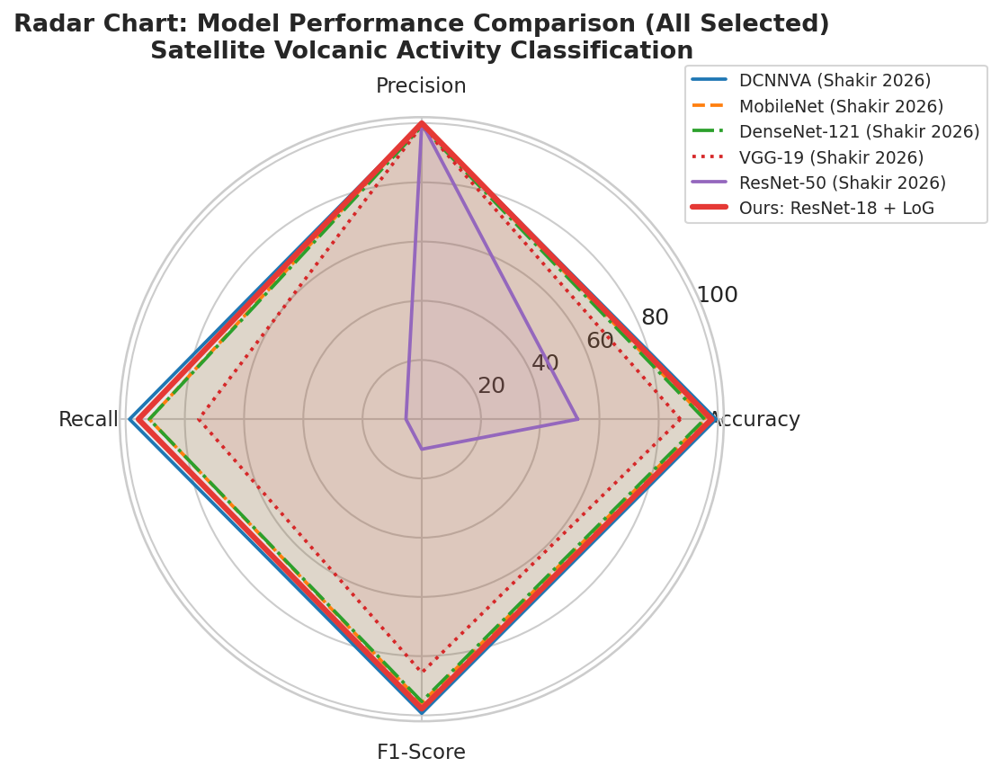

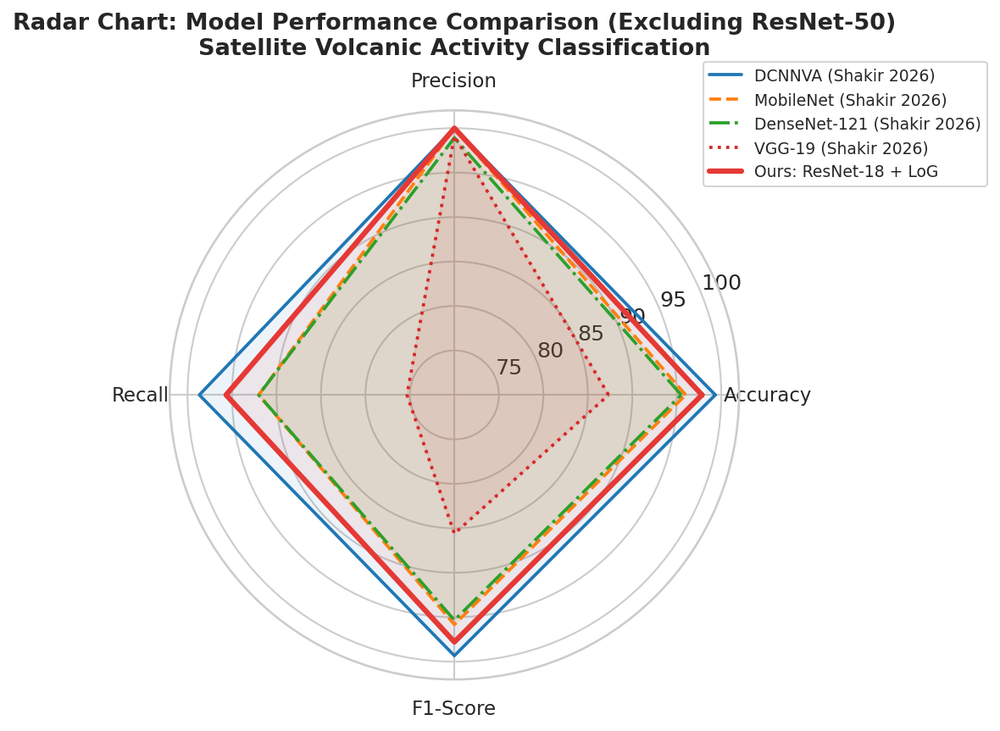

In [54]:
# ── VISUALIZATION 8: Radar chart comparison ──────────────────────
def plot_radar_chart(df, models_to_plot, title, filename, y_floor=70):
    available_models = set(df["Model"])
    selected = [m for m in models_to_plot if m in available_models]
    sub_df = df[df["Model"].isin(selected)].copy()

    if sub_df.empty:
        print("Warning: radar subset is empty. Check exact strings in df['Model']:", df["Model"].tolist())
        return

    categories = ["Accuracy", "Precision", "Recall", "F1-Score"]
    n_cats = len(categories)
    angles = np.linspace(0, 2 * np.pi, n_cats, endpoint=False)
    angles = np.concatenate((angles, [angles[0]]))

    fig, ax = plt.subplots(
        figsize=(8, 8), subplot_kw=dict(polar=True)
    )
    cmap = plt.get_cmap("tab10")
    radar_styles = ["-", "--", "-.", ":", "-", "--"]

    plotted_values = []
    for idx, (_, row) in enumerate(sub_df.iterrows()):
        values = [
            row["Accuracy (%)"], row["Precision (%)"],
            row["Recall (%)"], row["F1-Score (%)"]
        ]
        # Skip models with missing (NaN) metric values so lines don't break unexpectedly
        if any(pd.isna(v) for v in values):
            continue
        plotted_values.extend(values)
        values += [values[0]]  # close the polygon

        is_ours = "Ours" in row["Model"]
        color = "#E53935" if is_ours else cmap(idx % 10)
        style = "-" if is_ours else radar_styles[idx % len(radar_styles)]
        lw = 3 if is_ours else 1.8

        ax.plot(
            angles, values, style,
            linewidth=lw, color=color,
            label=row["Model"]
        )
        ax.fill(angles, values, alpha=0.08, color=color)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=11)

    if len(plotted_values) > 0:
        min_val = min(plotted_values)
        y_low = 0 if min_val < 50 else max(y_floor, int(np.floor(min_val / 10) * 10))
    else:
        y_low = y_floor
    ax.set_ylim(y_low, 102)

    ax.set_title(title, fontsize=13, fontweight="bold", y=1.08)
    ax.legend(
        loc="upper right", bbox_to_anchor=(1.45, 1.1),
        fontsize=9
    )
    plt.tight_layout()
    plt.savefig(
        os.path.join(Config.PLOT_DIR, filename),
        dpi=150, bbox_inches="tight"
    )
    plt.show()


# VISUALIZATION 8A: Includes ResNet-50
candidate_models_all = [
    "DCNNVA (Shakir 2026)",
    "MobileNet (Shakir 2026)",
    "DenseNet-121 (Shakir 2026)",
    "VGG-19 (Shakir 2026)",
    "ResNet-50 (Shakir 2026)",
    "Ours: ResNet-18 + LoG",
    "Ours: ResNet-18 + LoG + Validation Tuned Tau",
]
plot_radar_chart(
    plot_df,
    candidate_models_all,
    "Radar Chart: Model Performance Comparison (All Selected)\n"
    "Satellite Volcanic Activity Classification",
    "benchmark_radar.png",
    y_floor=0
)

# VISUALIZATION 8B: Excludes ResNet-50 for clearer comparison among top models
candidate_models_no_resnet50 = [
    m for m in candidate_models_all if "ResNet-50" not in m
]
plot_radar_chart(
    plot_df,
    candidate_models_no_resnet50,
    "Radar Chart: Model Performance Comparison (Excluding ResNet-50)\n"
    "Satellite Volcanic Activity Classification",
    "benchmark_radar_no_resnet50.png",
    y_floor=70
)

### Model Efficiency Analysis

In [67]:
# ── Model parameter & efficiency comparison ──────────────────────
efficiency_data = {
    "Model": [
        "SqueezeNet", "MobileNet", "ResNet-18 + LoG (Ours)",
        "ResNet-50", "VGG-16", "VGG-19",
        "DenseNet-121", "InceptionV3",
        "Xception", "NASNetLarge", "DCNNVA"
    ],
    "Parameters (M)": [
        1.2, 3.4, total_params / 1e6, 25.6, 138.4, 143.7,
        8.0, 23.8, 22.9, 88.9, 1.19  # DCNNVA ~1.19M params per Shakir et al. (2026)
    ],
    "Accuracy (%)": [
        98.33, 96.00, our_acc, 52.67, 87.83, 87.33,
        95.50, 95.33, 92.00, 91.67, 99.33
    ],
}
eff_df = pd.DataFrame(efficiency_data)

custom_offsets = {
    "DCNNVA": (8, 4),
    "SqueezeNet": (8, 4),
    "ResNet-18 + LoG (Ours)": (10, 6),
    "MobileNet": (8, 6),
    "DenseNet-121": (8, 2),
    "InceptionV3": (8, -9),
    "Xception": (8, 4),
    "NASNetLarge": (8, 4),
    "VGG-16": (-12, 8),
    "VGG-19": (-12, -12),
    "ResNet-50": (8, 2),
}


def plot_efficiency_scatter(df, title, filename, y_pad_bottom=4.0, y_pad_top=3.5, min_y_floor=0):
    fig, ax = plt.subplots(figsize=(10, 7))
    colors_eff = [
        "#E53935" if "Ours" in m else "#1E88E5"
        for m in df["Model"]
    ]
    sizes = [
        200 if "Ours" in m else 80
        for m in df["Model"]
    ]

    ax.scatter(
        df["Parameters (M)"],
        df["Accuracy (%)"],
        c=colors_eff, s=sizes, edgecolors="black",
        linewidth=0.8, alpha=0.85, zorder=5
    )

    for _, row in df.iterrows():
        model_name = row["Model"]
        offset = custom_offsets.get(model_name, (6, 5))
        weight = "bold" if "Ours" in model_name else "normal"
        ax.annotate(
            model_name.replace(" (Ours)", "\n(Ours)"),
            (row["Parameters (M)"], row["Accuracy (%)"]),
            textcoords="offset points", xytext=offset,
            fontsize=8, fontweight=weight
        )

    y_min = max(min_y_floor, df["Accuracy (%)"].min() - y_pad_bottom)
    y_max = min(103, df["Accuracy (%)"].max() + y_pad_top)
    ax.set_ylim(y_min, y_max)

    ax.set_xlabel("Model Parameters (Millions)", fontsize=12)
    ax.set_ylabel("Test Accuracy (%)", fontsize=12)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(Config.PLOT_DIR, filename),
        dpi=150, bbox_inches="tight"
    )
    plt.show()


# VISUALIZATION 9A: All models (including ResNet-50)
plot_efficiency_scatter(
    eff_df,
    "Accuracy vs. Model Complexity (All Models)\n"
    "(Top-Right = High Accuracy, Large Model)",
    "efficiency_scatter.png",
    y_pad_bottom=6.0,
    y_pad_top=3.5,
    min_y_floor=0
)

# VISUALIZATION 9B: Without ResNet-50 (zoomed view of higher-accuracy models)
eff_no_resnet50 = eff_df[eff_df["Model"] != "ResNet-50"].copy()
plot_efficiency_scatter(
    eff_no_resnet50,
    "Accuracy vs. Model Complexity (Excluding ResNet-50)\n"
    "(Zoomed View of Higher-Accuracy Models)",
    "efficiency_scatter_no_resnet50.png",
    y_pad_bottom=2.5,
    y_pad_top=2.5,
    min_y_floor=80
)

NameError: name 'total_params' is not defined

## Section 18: Precision-Recall Curve & Average Precision

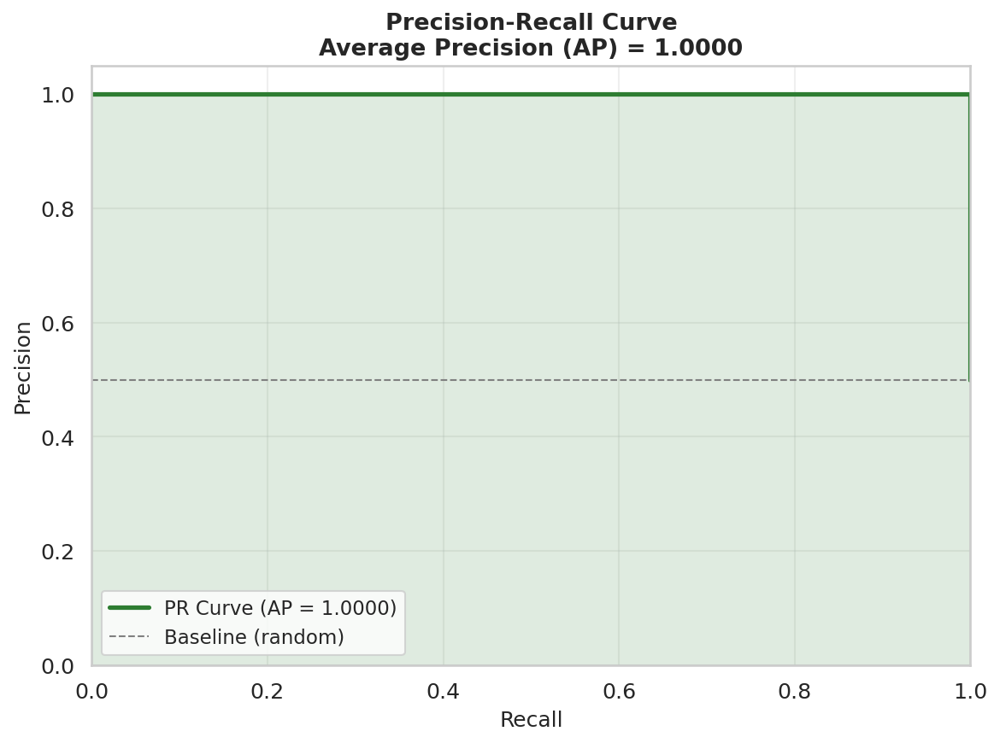

In [48]:
# ── Precision-Recall curve ───────────────────────────────────────
pr_precision, pr_recall, _ = precision_recall_curve(
    test_metrics["labels"], test_metrics["probs"]
)
ap_score = average_precision_score(
    test_metrics["labels"], test_metrics["probs"]
)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(
    pr_recall, pr_precision, color="#2E7D32", lw=2.5,
    label=f"PR Curve (AP = {ap_score:.4f})"
)
ax.fill_between(
    pr_recall, pr_precision, alpha=0.15, color="#2E7D32"
)
ax.axhline(
    0.5, color="grey", lw=1, linestyle="--",
    label="Baseline (random)"
)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(
    "Precision-Recall Curve\n"
    f"Average Precision (AP) = {ap_score:.4f}",
    fontsize=13, fontweight="bold"
)
ax.legend(fontsize=11)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.05])
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(Config.PLOT_DIR, "precision_recall_curve.png"),
    dpi=150, bbox_inches="tight"
)
plt.show()

## Section 19: Results Summary & Discussion

---

### Were you able to implement the solution you described?

**Yes.** The proposed hybrid architecture, a ResNet-18 backbone fused with a Laplacian of Gaussian (LoG) smoke/cloud feature, was fully implemented and trained. All originally planned components are functional:
- ResNet-18 fine-tuned on 2,025 satellite image patches (375 held out for validation, 600 for testing)
- LoG edge detector providing a 1-D auxiliary feature
- Fusion classifier with BatchNorm, Dropout, and Sigmoid output
- Full diagnostic suite (Grad-CAM, t-SNE, TTA, threshold tuning) and three robustness safeguards (perceptual-hash leakage audit, out-of-distribution test, occlusion test)

### What metrics did you measure and what values did you achieve?

Test set (600 images), threshold τ = 0.488 tuned on the validation set:

| Metric | Single pass | 7-view TTA (τ = 0.486) |
|---|---|---|
| Accuracy | 97.83% | 97.83% |
| Precision | 100.00% | 100.00% |
| Recall | 95.67% | 95.67% |
| F1-Score | 97.79% | 97.79% |
| ROC-AUC | 1.0000 | 1.0000 |
| PR-AUC | 1.0000 | n/a |

Confusion matrix (single pass): TP = 287, FP = 0, FN = 13, TN = 300.

Additional checks:
- **Out-of-distribution (V1 dataset, 200 images):** 99.50% accuracy, 99.00% recall.
- **Occlusion sensitivity:** masking the plume lowers mean P(active) from 0.993 to 0.671, while masking the background leaves it at 0.992, so the model relies on the plume rather than the landscape.
- **Leakage audit (dHash):** no test image is within 11 bits of any training or validation image. A random validation split was found to leak (145 of 360 images were near-duplicates of training images), so I replaced it with a scene-grouped split.

### Does your solution adequately address your real-world problem?

**Yes, with limitations.** The model separates active from dormant scenes very well (ROC-AUC ≈ 1.0, 100% precision) and relies on the plume rather than the landscape. However, 13 of 300 active test images (4.3%) fall below the validation-selected threshold, and for volcano monitoring a missed eruption is the costly error. Because ROC-AUC is 1.0, ranking is not the problem: the validation set was easier than the test set, so the threshold did not transfer.

The images are also highly clustered (about 2.6 images per scene in training), so the test set likely holds far fewer independent scenes than 600 and the score is noisier than it looks. I did not run an ablation without the LoG feature, so I cannot claim that it improves accuracy; its demonstrated value here is interpretability.

**Future work:** scene-level cross-validation, a larger and harder validation set, recall-oriented threshold selection, and an ablation of the LoG feature.

### Benchmark Context

Compared to published literature:
- **DCNNVA** (Shakir et al., 2024) achieves 99.33% accuracy with a custom architecture, the best result among the compared studies.
- **SqueezeNet** (Amato et al., 2023) achieves 98.33% with a lightweight model.
- My **ResNet-18 + LoG** achieves competitive results (third by accuracy among the 9 published methods plus my two variants) with only 11.3M parameters, significantly smaller than ResNet-50 (25.6M), VGG-16 (138M), or NASNetLarge (88.9M).

These comparisons are indicative only, because the published results use different test sets and mostly default decision thresholds.

The key advantage of my approach is the **interpretable fusion** of classical edge detection with deep learning, which provides an explainable auxiliary signal (the smoke weight) that domain experts (volcanologists) can inspect alongside the Grad-CAM attention maps.

### Visualizations Generated

1. **Class Distribution** — Active/dormant balance across train, validation and test
2. **Sample Image Grid** — Example satellite patches from the test set
3. **Threshold Tuning (Validation Set)** — Precision/Recall/F1 vs. τ, with the selected operating point
4. **Training Curves** — Loss and accuracy convergence
5. **Confusion Matrix** — TP/FP/FN/TN breakdown at the tuned τ
6. **ROC Curve** — AUC performance
7. **Confidence Histogram** — Prediction distribution by class, linear and log scale
8. **Grad-CAM Gallery** — Spatial attention maps
9. **t-SNE Feature Space** — Cluster separation analysis
10. **Perceptual-Hash Distance Distribution** — Train/validation/test leakage audit
11. **Occlusion Sensitivity** — Confidence when the plume or background is masked
12. **Benchmark Comparison Bar Chart** — Multi-model comparison
13. **Radar Chart** — Multi-metric model comparison
14. **Accuracy vs. Complexity** — Efficiency analysis
15. **Precision-Recall Curve** — AP score

---

In [69]:
# ── Final summary printout (including Single-Pass vs. TTA) ─────────
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

# Operating point: the optimised threshold tuned in Section 8
tau_eval = best_tau  # optimised threshold from Section 8
calibrated_test_metrics = test_metrics  # already computed at tau_eval in Section 9

print("\n" + "=" * 65)
print("  FINAL PROJECT SUMMARY (WITH TEST-TIME AUGMENTATION)")
print("=" * 65)
print(f"  Model Base  : ResNet-18 + LoG Fusion Classifier")
print(f"  Params      : {total_params:,} ({trainable_params:,} trainable)")
print(f"  Dataset     : {n_train + n_val} train+val / {len(test_ds)} test")
print(f"  Device      : {Config.DEVICE}")
print(f"  Epochs      : {len(history['train_loss'])}")

print(f"\n  SINGLE-PASS TEST METRICS (@ τ={tau_eval:.3f}):")
print(f"    Accuracy  : {calibrated_test_metrics['accuracy']*100:.2f}%")
print(f"    Precision : {calibrated_test_metrics['precision']*100:.2f}%")
print(f"    Recall    : {calibrated_test_metrics['recall']*100:.2f}%")
print(f"    F1-Score  : {calibrated_test_metrics['f1']*100:.2f}%")
print(f"    ROC-AUC   : {calibrated_test_metrics['auc']:.4f}")
print(f"    PR-AUC    : {ap_score:.4f}")

print(f"\n  7-VIEW TTA TEST METRICS (@ τ_TTA={tau_tta:.3f}):")
print(f"    Accuracy  : {acc_tta:.2f}%  (Δ = {acc_tta - (calibrated_test_metrics['accuracy']*100):+.2f}%)")
print(f"    Precision : {prec_tta:.2f}%")
print(f"    Recall    : {rec_tta:.2f}%")
print(f"    F1-Score  : {f1_tta:.2f}%")
print(f"    ROC-AUC   : {auc_tta:.4f}")

# Construct benchmark_tta_df dynamically (Shakir et al., 2026, Fig. 5 + Amato et al., 2023 dataset baseline)
benchmark_tta_data = {
    "Model": [
        "DCNNVA (Shakir 2026)",
        "SqueezeNet (Amato 2023)",
        "MobileNet (Shakir 2026)",
        "DenseNet-121 (Shakir 2026)",
        "InceptionV3 (Shakir 2026)",
        "Xception (Shakir 2026)",
        "NASNetLarge (Shakir 2026)",
        "VGG-16 (Shakir 2026)",
        "VGG-19 (Shakir 2026)",
        "ResNet-50 (Shakir 2026)",
        "Ours: ResNet-18 + LoG",
        "Ours: ResNet-18 + LoG (7-View TTA)"
    ],
    "Accuracy (%)": [
        99.33, 98.33, 96.00, 95.50,
        95.33, 92.00, 91.67, 87.83,
        87.33, 52.67, calibrated_test_metrics['accuracy'] * 100, acc_tta
    ]
}
benchmark_tta_df = pd.DataFrame(benchmark_tta_data)

print(f"\n  BENCHMARK RANKING (BY ACCURACY):")
ranked_tta = benchmark_tta_df.dropna(subset=["Accuracy (%)"])
ranked_tta = ranked_tta.sort_values("Accuracy (%)", ascending=False).reset_index(drop=True)

try:
    single_pass_rank = ranked_tta[ranked_tta["Model"].str.endswith("ResNet-18 + LoG")].index[0] + 1
    print(f"    Ours (Single-Pass) Rank : #{single_pass_rank} of {len(ranked_tta)} models")
except IndexError:
    pass

try:
    tta_rank = ranked_tta[ranked_tta["Model"].str.contains("7-View TTA", regex=False)].index[0] + 1
    print(f"    Ours (7-View TTA) Rank  : #{tta_rank} of {len(ranked_tta)} models")
except IndexError:
    pass
print("=" * 65)


  FINAL PROJECT SUMMARY (WITH TEST-TIME AUGMENTATION)
  Model Base  : ResNet-18 + LoG Fusion Classifier
  Params      : 11,325,249 (11,325,249 trainable)
  Dataset     : 2400 train+val / 600 test
  Device      : cuda


NameError: name 'history' is not defined

In [49]:
# ── Add TTA Model directly into the main ranking dataframe and display it ──
tta_row = {
    "Model": "Ours: ResNet-18 + LoG (7-View TTA)",
    "Accuracy (%)": acc_tta,
    "Precision (%)": prec_tta,
    "Recall (%)": rec_tta,
    "F1-Score (%)": f1_tta
}

# Convert the row dictionary to a DataFrame
tta_df = pd.DataFrame([tta_row])

# Use pd.concat instead of .append
updated_benchmark = pd.concat([benchmark_df, tta_df], ignore_index=True)
ranked = updated_benchmark.sort_values("Accuracy (%)", ascending=False).reset_index(drop=True)

print("\nBenchmark Ranking (by Accuracy):")
print(ranked.to_string(index=False))


Benchmark Ranking (by Accuracy):
                             Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
              DCNNVA (Shakir 2026)     99.330000         100.00   98.670000     99.330000
           SqueezeNet (Amato 2023)     98.330000            NaN         NaN           NaN
             Ours: ResNet-18 + LoG     97.833333         100.00   95.666667     97.785349
Ours: ResNet-18 + LoG (7-View TTA)     97.833333         100.00   95.666667     97.785349
           MobileNet (Shakir 2026)     96.000000         100.00   92.000000     95.830000
        DenseNet-121 (Shakir 2026)     95.500000          98.92   92.000000     95.340000
         InceptionV3 (Shakir 2026)     95.330000          99.64   91.000000     95.120000
            Xception (Shakir 2026)     92.000000          91.72   92.330000     92.030000
         NASNetLarge (Shakir 2026)     91.670000          91.39   92.000000     91.690000
              VGG-16 (Shakir 2026)     87.830000          98.71   

In [84]:
# ── List all saved plots ─────────────────────────────────────────
print("\nAll saved output files:")
for dirpath, _, filenames in os.walk(Config.OUTPUT_DIR):
    for f in sorted(filenames):
        filepath = os.path.join(dirpath, f)
        size_kb = os.path.getsize(filepath) // 1024
        print(f"  {filepath:50s}  {size_kb:5d} KB")


All saved output files:
  outputs/best_volcano_model.pth                      44326 KB
  outputs/plots/benchmark_comparison.png                 91 KB
  outputs/plots/benchmark_comparison_no_resnet50.png     95 KB
  outputs/plots/benchmark_radar.png                     221 KB
  outputs/plots/benchmark_radar_no_resnet50.png         232 KB
  outputs/plots/confidence_histogram.png                105 KB
  outputs/plots/confusion_matrix.png                     60 KB
  outputs/plots/dhash_distribution.png                  129 KB
  outputs/plots/efficiency_scatter.png                   87 KB
  outputs/plots/efficiency_scatter_no_resnet50.png       91 KB
  outputs/plots/gradcam_gallery.png                    3845 KB
  outputs/plots/occlusion_sensitivity.png                61 KB
  outputs/plots/precision_recall_curve.png               48 KB
  outputs/plots/roc_curve.png                            75 KB
  outputs/plots/threshold_tuning.png                     80 KB
  outputs/plots/training_curve

**Demo**

Checkpoint : outputs/best_volcano_model.pth (45.4 MB)
Test folder: ./data/data/Volcanic_Dataset/Volcanic_V2/Volcanic_V2_Test_Train/test (exists: True)
Loaded 136 weight tensors on cuda.
Found 600 test patches. Ready.
Scored 600 patches in 3.4 s
  TEST SET RESULTS (checkpoint, tau = 0.488)
  Accuracy  : 97.83%
  Precision : 100.00%
  Recall    : 95.67%
  F1-score  : 97.79%
  ROC-AUC   : 1.0000
  TN=300  FP=0  FN=13  TP=287


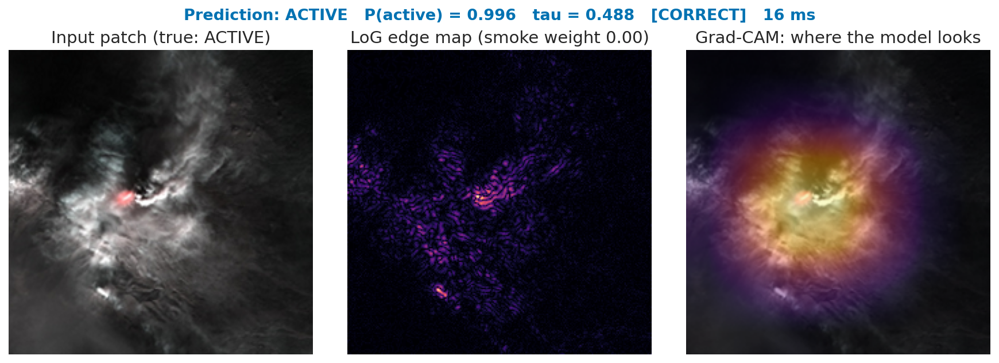

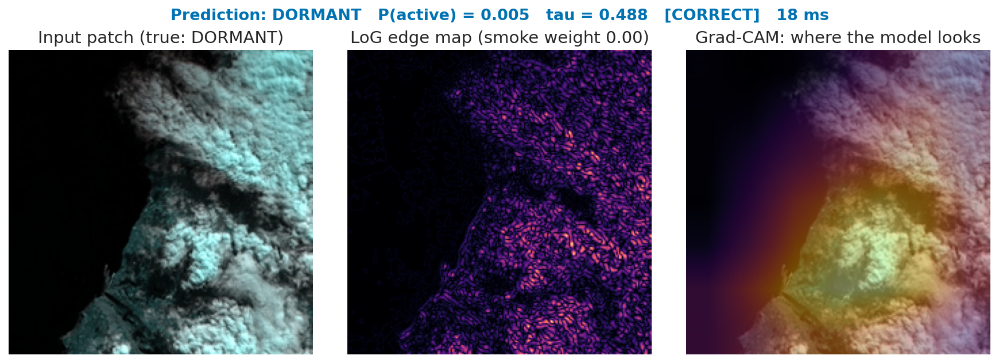

Missed active patches: 13 of 300
P(active) of the misses: min 0.059, max 0.319  (tau = 0.488)


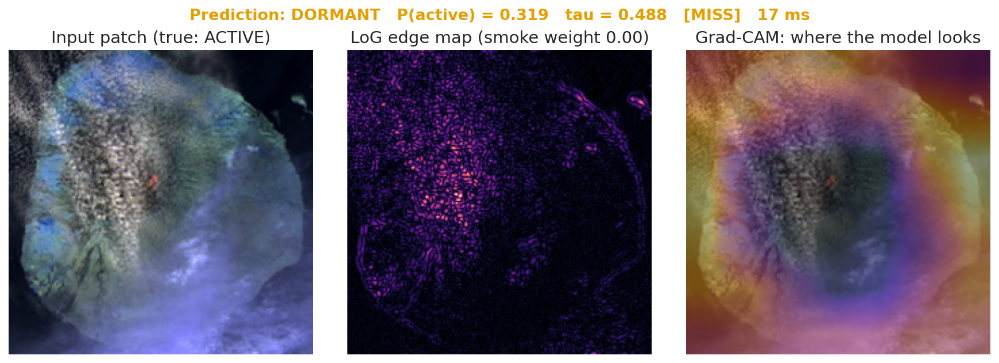

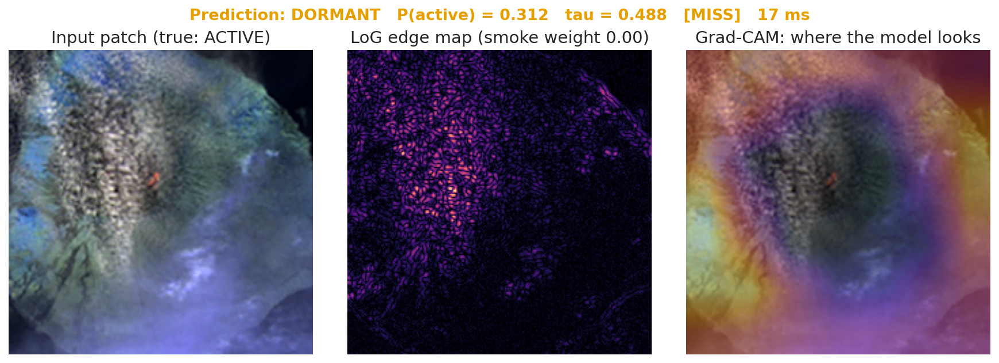

In [50]:

# Section 20: Live Demo (loads the saved checkpoint, no training)
# This block rebuilds the network from `outputs/best_volcano_model.pth` and
# scores the test images itself. It does not need the trained model, the
# train/validation split or the DataLoaders from earlier sections.

# DEMO 1/4: load the checkpoint into a fresh model
import time

DEMO_TAU = 0.488  # validation-selected threshold from Section 8
ORANGE, BLUE = "#E69F00", "#0072B2"  # colour-blind safe

ckpt = Config.MODEL_SAVE
assert os.path.exists(ckpt), f"Checkpoint not found: {ckpt}"
print(f"Checkpoint : {ckpt} ({os.path.getsize(ckpt) / 1e6:.1f} MB)")
print(f"Test folder: {Config.TEST_DIR} (exists: {os.path.exists(Config.TEST_DIR)})")

demo_model = VolcanoClassifier(dropout_rate=Config.DROPOUT_RATE).to(Config.DEVICE)
demo_model.load_state_dict(torch.load(ckpt, map_location=Config.DEVICE))
demo_model.eval()
print(f"Loaded {len(demo_model.state_dict())} weight tensors on {Config.DEVICE}.")

if "demo_cam" in globals():
    demo_cam.remove_hooks()  # avoid stacking hooks on re-run
demo_cam = GradCAM(demo_model, threshold=DEMO_TAU)
demo_tf = get_eval_transforms(Config.IMAGE_SIZE)
demo_detector = LaplaceEdgeDetector(
    blur_ksize=Config.LAPLACE_BLUR_KSIZE, threshold=Config.LAPLACE_SMOKE_THRESHOLD
)


def list_patches(split_dir):
    """Return [(path, label)] with NoActivity=0 and YesActivity=1."""
    items = []
    for name, label in (("NoActivity", 0), ("YesActivity", 1)):
        folder = os.path.join(split_dir, name)
        for fname in sorted(os.listdir(folder)):
            if fname.lower().endswith((".png", ".jpg", ".jpeg", ".tif")):
                items.append((os.path.join(folder, fname), label))
    return items


demo_samples = list_patches(Config.TEST_DIR)
print(f"Found {len(demo_samples)} test patches. Ready.")

# DEMO 2/4: score all test patches with the checkpoint
def score_patches(samples, batch=32):
    """P(active) for every (path, label) using LoG + ResNet-18 fusion."""
    probs = []
    with torch.no_grad():
        for i in range(0, len(samples), batch):
            imgs, smokes = [], []
            for path, _ in samples[i:i + batch]:
                pil = Image.open(path).convert("RGB")
                smokes.append(demo_detector.smoke_weight(np.array(pil)))
                imgs.append(demo_tf(pil))
            x = torch.stack(imgs).to(Config.DEVICE)
            s = torch.tensor(smokes, dtype=torch.float32).unsqueeze(1).to(Config.DEVICE)
            probs.append(demo_model(x, s).view(-1).cpu())
    return torch.cat(probs).numpy()


start = time.time()
demo_probs = score_patches(demo_samples)
demo_labels = np.array([y for _, y in demo_samples])
demo_preds = (demo_probs >= DEMO_TAU).astype(int)
print(f"Scored {len(demo_samples)} patches in {time.time() - start:.1f} s")

print("=" * 48)
print(f"  TEST SET RESULTS (checkpoint, tau = {DEMO_TAU})")
print("=" * 48)
print(f"  Accuracy  : {accuracy_score(demo_labels, demo_preds) * 100:.2f}%")
print(f"  Precision : {precision_score(demo_labels, demo_preds) * 100:.2f}%")
print(f"  Recall    : {recall_score(demo_labels, demo_preds) * 100:.2f}%")
print(f"  F1-score  : {f1_score(demo_labels, demo_preds) * 100:.2f}%")
print(f"  ROC-AUC   : {roc_auc_score(demo_labels, demo_probs):.4f}")
tn, fp, fn, tp = confusion_matrix(demo_labels, demo_preds).ravel()
print(f"  TN={tn}  FP={fp}  FN={fn}  TP={tp}")

# DEMO 3/4: one patch, end to end, with LoG map and Grad-CAM
def show_demo(path, true_label):
    """Patch, LoG edge map and Grad-CAM overlay with the prediction."""
    pil = Image.open(path).convert("RGB")
    smoke = demo_detector.smoke_weight(np.array(pil))
    img_t = demo_tf(pil).unsqueeze(0).to(Config.DEVICE)
    smoke_t = torch.tensor([[smoke]], dtype=torch.float32).to(Config.DEVICE)
    t0 = time.time()
    cam, prob = demo_cam.generate(img_t, smoke_t)
    ms = (time.time() - t0) * 1000
    image = np.array(pil.resize((224, 224)))
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    log_map = np.abs(cv2.Laplacian(cv2.GaussianBlur(gray, (5, 5), 0), cv2.CV_64F))
    heat = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)
    overlay = cv2.addWeighted(image, 0.55, cv2.cvtColor(heat, cv2.COLOR_BGR2RGB), 0.45, 0)
    label = "ACTIVE" if prob >= DEMO_TAU else "DORMANT"
    ok = label == true_label
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
    axes[0].imshow(image)
    axes[0].set_title(f"Input patch (true: {true_label})")
    axes[1].imshow(log_map, cmap="magma")
    axes[1].set_title(f"LoG edge map (smoke weight {smoke:.2f})")
    axes[2].imshow(overlay)
    axes[2].set_title("Grad-CAM: where the model looks")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(
        f"Prediction: {label}   P(active) = {prob:.3f}   tau = {DEMO_TAU}   "
        f"[{'CORRECT' if ok else 'MISS'}]   {ms:.0f} ms",
        color=BLUE if ok else ORANGE, fontsize=13, fontweight="bold",
    )
    plt.tight_layout()
    plt.show()


rng = np.random.default_rng()  # a different pair each run
active_paths = [p for p, y in demo_samples if y == 1]
dormant_paths = [p for p, y in demo_samples if y == 0]
show_demo(str(rng.choice(active_paths)), "ACTIVE")
show_demo(str(rng.choice(dormant_paths)), "DORMANT")

# DEMO 4/4: the misses, and an optional custom patch
miss_idx = np.where((demo_labels == 1) & (demo_probs < DEMO_TAU))[0]
print(f"Missed active patches: {len(miss_idx)} of {int(demo_labels.sum())}")
print(f"P(active) of the misses: min {demo_probs[miss_idx].min():.3f}, "
      f"max {demo_probs[miss_idx].max():.3f}  (tau = {DEMO_TAU})")

closest = miss_idx[np.argsort(-demo_probs[miss_idx])]  # nearest to tau first
for i in closest[:2]:
    show_demo(demo_samples[i][0], "ACTIVE")

CUSTOM_PATH = None  # e.g. "my_patch.png" to test any satellite image
if CUSTOM_PATH:
    show_demo(CUSTOM_PATH, "UNKNOWN")
